# Per-channel, channel-averaged and CCA-projected EEG spectra — 30 October 2026

Based on `cca_joint_projection_power.ipynb`, with three views of the same EEG: each channel separately, the arithmetic channel mean, and independent U17/U19 CCA projections. Inspection shows C9–C24; downstream means and CCA use the editable `SELECTED_CHANNELS` list, at 250 Hz and the epoch duration set by `EPOCH_SECONDS` (currently **five seconds**).

The first spectral section contains **six per-channel grids** (96 panels), followed by 12 channel-average figures and 24 CCA figures. CCA figures retain whole-trial and logged-update refitted weights and both averaging orders.

**Available EEG: 100 complete marked trials — 52 Paddle v2 and 48 Leaf.** The first two Paddle blocks and both Leaf blocks each supply 24 trials. The third Paddle game log contains 24 trials, but `eeg_20261030_124401` contains only the tail of trial 20 and complete trials 21–24. Trials 1–20 of that block are excluded because complete EEG boundaries are unavailable. `eeg_20261030_124553` contains no nonzero signal markers; the fourth Paddle game log is empty. Neither supplies additional trial data. No missing EEG is interpolated or inferred from the game trace.

Paddle groups refer to the **initial direction cue**: a complete v2 trial can reverse direction in later phases. These are whole-trial spectra grouped by initial cue, not phase-specific attention spectra. Paddle and Leaf logs also use different participant labels (`p23` and `p5`); these labels are retained as provenance and are not treated as verified participant identity.

Inspection figures and recording audits are saved in the configured epoch folder under `plots`; downstream figures and audits are saved in a channel-selection subfolder. Complete trials receive equal weight, so the truncated third Paddle block contributes only its four available trials. This is a descriptive analysis of the recorded subset, not an estimate of the missing full block.

Choose channels in the editable list immediately after the per-channel inspection grids, then run that cell and every cell below it. The saved channel list and figure captions identify the channels used.

In [1]:
from pathlib import Path
from functools import lru_cache
import base64
import html
import io
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import HTML, display

ROOT = Path.cwd()
if not (ROOT / 'data/2026-10-30').is_dir():
    ROOT = Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT = ROOT / 'data/2026-10-30'
PLOT_EXPORT_DPI = 200
FILES = {'Paddle v2': ('eeg_20261030_114700', 'eeg_20261030_120516', 'eeg_20261030_124401'),
         'Leaf': ('eeg_20261030_121520', 'eeg_20261030_122929')}
LABELS = {'Paddle v2': {20: 'Left initial cue', 21: 'Right initial cue'},
          'Leaf': {20: 'C1 / Pointing', 21: 'C2 / Moving'}}
RECORDING_SPECS = [
    ('Paddle v2', 1, 'eeg_20261030_114700', 'p23_b01_paddle_multidir_trialdata.csv', 1),
    ('Paddle v2', 2, 'eeg_20261030_120516', 'p23_b02_paddle_multidir_trialdata.csv', 1),
    ('Leaf', 1, 'eeg_20261030_121520', 'p5_b01_leaves_trialdata.csv', 1),
    ('Leaf', 2, 'eeg_20261030_122929', 'p5_b02_leaves_trialdata.csv', 1),
    ('Paddle v2', 3, 'eeg_20261030_124401', 'p23_b03_paddle_multidir_trialdata.csv', 21),
    ('Paddle v2', 4, 'eeg_20261030_124553', 'p23_b04_paddle_multidir_trialdata.csv', None),
]
RECORDED_CHANNEL_COLUMNS = [f'ch{i}_uv' for i in range(9, 25)]
RECORDED_CHANNEL_NAMES = [f'C{i}' for i in range(9, 25)]
CHANNEL_COLUMNS = RECORDED_CHANNEL_COLUMNS.copy()
CHANNEL_NAMES = RECORDED_CHANNEL_NAMES.copy()
FS, TARGETS_HZ = 250.0, (17.0, 19.0)
CHANNEL_PSD_FREQ_LIMITS = (5.0, 40.0)
NF_WINDOW_SECONDS, NF_HOP_SECONDS = 1.0, 0.1
WINDOW_SAMPLES = int(round(FS * NF_WINDOW_SECONDS))
HOP_SAMPLES = int(round(FS * NF_HOP_SECONDS))
# Fixed electrode polarity convention, not reference-phase alignment.
SIGN_ANCHOR_CHANNEL = 'ch16_uv'
SIGN_ANCHOR_INDEX = CHANNEL_COLUMNS.index(SIGN_ANCHOR_CHANNEL)
# None shows all NF points; set a duration only to restrict the displayed maps.
PLOT_MAX_SECONDS, FREQ_LIMITS = None, (5.0, 30.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10})
# Overview spectra retain complete variable-duration trials.
EPOCH_SECONDS = 5.0
EPOCH_SAMPLES = int(round(FS * EPOCH_SECONDS))
INSPECTION_EXPORT_DIR = ROOT / 'plots' / f'2026-10-30_cca_epoch_spectra_{EPOCH_SECONDS:g}s'
INSPECTION_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_EXPORT_DIR = INSPECTION_EXPORT_DIR

## Load recordings, recover CCA endpoints and audit coverage

The EEG CSV columns are `filt9`–`filt24` (filtered microvolts). They are renamed to the reference notebook's `ch9_uv`–`ch24_uv` internally. Session metadata verifies the sampling rate and physical channel map. No additional filtering or channel averaging is applied.

Today's feature CSVs omit `is_cca` and contain both SMI and CCA rows at each sequence number. Recover actual CCA endpoints directly from the binary feature records: little-endian 112-byte records, `uint8 is_cca`, `uint8 reserved`, `uint16 marker`, `uint32 seq`, then 26 float32 values. Only `is_cca == 1` endpoints enter the refits. This format is defined in CogLab-Games `Packages/org.iisc.bcicore.server/Runtime/Logging/CsvSessionLogger.cs` and `BinToCsvConverter.cs`. Do not infer CCA timing from nonzero alpha values or alternating CSV rows.

Trigger meanings checked against `Assets/Games/Paddle_MultiDir/Scripts/PaddleMultiDirGameController.cs` and `Assets/Games/Leaf/Scripts/LeafGameController.cs`:

| Marker | Paddle v2 | Leaf |
|---|---|---|
| 20 | Start with left cue | Start C1 / Pointing |
| 21 | Start with right cue | Start C2 / Moving |
| 30 | Trial stop | Trial stop |
| 39 | First cued edge reached | — |
| 40 | Centre reached | Response |
| 41 / 42 | Final phase left / right cue | — |
| 45 | — | Cue onset in pre-cue mode (absent today) |
| 50 | — | Colour reveal / success event |

Only 20/21 start trials; pair each with the first 30 before the next start. Internal phase/response markers remain inside the trial. Paddle `TargetSide` is logged at trial end and can differ from the initial cue after a direction change, so the EEG start marker defines the group. Trial durations and relative onset timing validate the game-log alignment; for the partial recording the matching suffix is trials 21–24. Missing and orphan boundaries are exported, not silently repaired.

In [2]:
def marker_starts(markers, values):
    return np.flatnonzero(np.isin(markers, values) &
                         np.r_[True, markers[1:] != markers[:-1]])

FEATURE_DTYPE = np.dtype([('is_cca', 'u1'), ('reserved', 'u1'),
    ('marker', '<u2'), ('seq', '<u4'), ('values', '<f4', (26,))])
assert FEATURE_DTYPE.itemsize == 112

def load_cca_endpoints(folder, stamp):
    path = folder / f'{stamp}_features.bin'
    if path.stat().st_size % FEATURE_DTYPE.itemsize:
        raise ValueError(f'{stamp}: incomplete binary feature record')
    features = np.fromfile(path, dtype=FEATURE_DTYPE)
    if not np.isin(features['is_cca'], [0, 1]).all() or np.any(features['reserved'] != 0):
        raise ValueError(f'{stamp}: unexpected binary feature format')
    csv_seq = pd.read_csv(folder / f'{stamp}_features.csv', usecols=['seq']).seq.to_numpy(np.int64)
    if not np.array_equal(csv_seq, features['seq']):
        raise ValueError(f'{stamp}: binary/CSV feature sequences disagree')
    nf = features['seq'][features['is_cca'] == 1].astype(np.int64)
    return np.unique(nf), len(nf)-len(np.unique(nf)), len(features)

records, trials, recording_rows, marker_rows, boundary_rows, coverage_rows = [], [], [], [], [], []
for game, block, stamp, log_name, first_game_trial in RECORDING_SPECS:
    folder = DATA_ROOT / stamp
    meta = json.loads((folder / f'{stamp}_meta.json').read_text(encoding='utf-8-sig'))
    if meta['fs'] != FS or meta['num_ch'] != 16 or meta['ch_map'] != list(range(8, 24)):
        raise ValueError(f'{stamp}: unexpected montage or sample rate')
    csv_columns = [f'filt{i}' for i in range(9, 25)]
    s = pd.read_csv(folder / f'{stamp}_signals.csv', usecols=['seq', 'marker', *csv_columns])
    s = s.rename(columns=dict(zip(csv_columns, RECORDED_CHANNEL_COLUMNS)))
    seq, markers = s.seq.to_numpy(np.int64), s.marker.to_numpy(np.int64)
    x = s[RECORDED_CHANNEL_COLUMNS].to_numpy(float)
    if len(seq) < WINDOW_SAMPLES or np.any(np.diff(seq) <= 0):
        raise ValueError(f'{stamp}: signal sequences must be unique and increasing')
    nfseq, duplicate_nf_rows, feature_rows = load_cca_endpoints(folder, stamp)
    starts, ends = marker_starts(markers, (20, 21)), marker_starts(markers, (30,))
    events = marker_starts(markers, tuple(v for v in np.unique(markers) if v != 0))
    for pos in events:
        marker_rows.append(dict(game=game, block=block, recording=stamp,
                                seq=int(seq[pos]), marker=int(markers[pos])))
    rec = dict(game=game, recording=stamp, block=block, x=x, recorded_x=x, seq=seq, nfseq=nfseq)
    records.append(rec)
    log = pd.read_csv(DATA_ROOT / 'gameData' / log_name)
    paired, used_ends, block_trials = 0, set(), []
    for j, start in enumerate(starts):
        next_start = starts[j+1] if j+1 < len(starts) else len(seq)
        candidates = ends[(ends > start) & (ends < next_start)]
        if not len(candidates):
            boundary_rows.append(dict(recording=stamp, seq=int(seq[start]), marker=int(markers[start]),
                                      status='start without stop before next start / recording end'))
            continue
        stop = int(candidates[0]); used_ends.add(stop)
        if first_game_trial is None:
            raise ValueError(f'{stamp}: unexpected trials in the marker-free recording')
        number = first_game_trial + j
        trial = dict(uid=f'{stamp}/trial{number}', rec=rec, game=game, block=block,
            trial=number, condition=LABELS[game][int(markers[start])], marker=int(markers[start]),
            start=int(start), stop=stop, start_seq=int(seq[start]), stop_seq=int(seq[stop]),
            x=x[start:stop], recorded_x=x[start:stop], seconds=(seq[stop]-seq[start])/FS, windows=[])
        trials.append(trial); block_trials.append(trial); paired += 1
    for stop in ends:
        if int(stop) not in used_ends:
            boundary_rows.append(dict(recording=stamp, seq=int(seq[stop]), marker=30,
                status='stop without observed start; incomplete trial excluded'))
    offsets = []
    duration_errors = []
    for trial in block_trials:
        match = log.loc[log.TrialNumber.eq(trial['trial'])]
        if len(match) != 1: raise ValueError(f'{trial["uid"]}: no unique game-log trial')
        row = match.iloc[0]
        expected_seconds = float(row.TrialEnd-row.TrialStart)
        residual = trial['seconds']-expected_seconds
        if abs(residual) > .15:
            raise ValueError(f'{trial["uid"]}: game/EEG duration mismatch ({residual:.3f} s)')
        if game == 'Leaf' and int(trial['marker']) != {'c1': 20, 'c2': 21}[row.Cue.lower()]:
            raise ValueError(f'{trial["uid"]}: game/EEG cue mismatch')
        offsets.append(trial['start_seq']/FS-float(row.TrialStart))
        duration_errors.append(abs(residual))
    offset_spread = float(np.ptp(offsets)) if offsets else np.nan
    if offsets and offset_spread > 1.0:
        raise ValueError(f'{stamp}: game-log relative onset timing disagrees ({offset_spread:.3f} s)')
    by_number = {t['trial']: t for t in block_trials}
    for _, row in log.iterrows():
        number = int(row.TrialNumber)
        trial = by_number.get(number)
        coverage_rows.append(dict(game=game, block=block, recording=stamp, game_log=log_name,
            game_trial=number, status='complete EEG trial' if trial else 'no complete EEG trial',
            condition=trial['condition'] if trial else '',
            eeg_seconds=trial['seconds'] if trial else np.nan,
            game_seconds=float(row.TrialEnd-row.TrialStart),
            duration_error_seconds=trial['seconds']-float(row.TrialEnd-row.TrialStart) if trial else np.nan))
    recording_rows.append(dict(game=game, block=block, recording=stamp, game_log=log_name,
        channels=x.shape[1], samples=len(seq), trials=paired, game_log_trials=len(log),
        unmatched_starts=len(starts)-paired, unmatched_stops=len(ends)-len(used_ends),
        signal_gap_events=int(np.count_nonzero(np.diff(seq) != 1)),
        nonfinite_signal_values=int((~np.isfinite(x)).sum()),
        logged_nf_updates=len(nfseq), duplicate_nf_rows=duplicate_nf_rows,
        median_nf_hop_seconds=float(np.median(np.diff(nfseq))/FS),
        max_nf_hop_seconds=float(np.max(np.diff(nfseq))/FS),
        feature_rows=feature_rows, metadata_samples_minus_csv=int(meta['signals_samples']-len(seq)),
        onset_offset_spread_seconds=offset_spread,
        max_game_duration_error_seconds=max(duration_errors) if duration_errors else np.nan,
        note='EEG starts during trial 20; only trials 21-24 complete' if first_game_trial == 21 else
             'No trial markers; empty game log' if first_game_trial is None else 'Complete block'))

recording_audit = pd.DataFrame(recording_rows)
marker_audit = pd.DataFrame(marker_rows)
boundary_audit = pd.DataFrame(boundary_rows)
coverage_audit = pd.DataFrame(coverage_rows)
for name, table in [('recording_audit', recording_audit), ('marker_events', marker_audit),
                    ('boundary_audit', boundary_audit), ('game_trial_coverage', coverage_audit)]:
    table.to_csv(INSPECTION_EXPORT_DIR / f'{name}.csv', index=False)
# Check recorded Leaf stimulus frequencies, rather than relying on CSV feature labels.
for path in sorted((DATA_ROOT / 'gameData').glob('*leaves_ssvepframes.csv')):
    frequencies = pd.read_csv(path, usecols=['FrequencyC1Hz', 'FrequencyC2Hz']).drop_duplicates()
    assert len(frequencies) == 1 and np.allclose(frequencies.iloc[0], TARGETS_HZ)
assert len(trials) == 100
assert coverage_audit.status.eq('complete EEG trial').sum() == 100
assert len(coverage_audit) == 120
print(f'{len(trials)} complete trials; {len(RECORDED_CHANNEL_COLUMNS)} channels; {FS:g} Hz')
display(recording_audit[['game', 'block', 'recording', 'trials', 'game_log_trials', 'signal_gap_events', 'note']])
display(coverage_audit.groupby(['game', 'block', 'status']).size().rename('trials').to_frame())
print('Excluded: Paddle block 3 trials 1-20 lack complete EEG. Block 4 has no game trials/markers.')
print('Some metadata sample totals exceed CSV rows by 1-3; observed CSV sequences define coverage.')

100 complete trials; 16 channels; 250 Hz
Excluded: Paddle block 3 trials 1-20 lack complete EEG. Block 4 has no game trials/markers.
Some metadata sample totals exceed CSV rows by 1-3; observed CSV sequences define coverage.


,game,block,recording,trials,game_log_trials,signal_gap_events,note
0,Paddle v2,1,eeg_20261030_114700,24,24,0,Complete block
1,Paddle v2,2,eeg_20261030_120516,24,24,0,Complete block
2,Leaf,1,eeg_20261030_121520,24,24,0,Complete block
3,Leaf,2,eeg_20261030_122929,24,24,0,Complete block
4,Paddle v2,3,eeg_20261030_124401,4,24,0,EEG starts during trial 20; only trials 21-24 ...
5,Paddle v2,4,eeg_20261030_124553,0,0,0,No trial markers; empty game log


trials
game      block status                       
Leaf      1     complete EEG trial         24
          2     complete EEG trial         24
Paddle v2 1     complete EEG trial         24
          2     complete EEG trial         24
          3     complete EEG trial          4
                no complete EEG trial      20

## Per-channel average power spectra

Inspect each recorded channel **C9–C24 separately**, before channel averaging or CCA. Six 4×4 grids cover Paddle v2 and Leaf, each split into its two initial-cue groups and all available complete trials. Panel titles show the physical channel number.

For each channel, calculate the PSD of every observed epoch, average epoch PSDs within each trial, then average trials equally **in linear power** before converting to dB. Epoch length follows `EPOCH_SECONDS` in the settings cell (currently five seconds). This uses the same trial boundaries, DPSS taper (NW=1, K=1), FFT grid and treatment of partial epochs as the later analyses. No channel mixing, CCA, phase alignment or additional filtering is used.

The overview spans **5–40 Hz**, including the 17/19 Hz stimulus frequencies. The frequency range is controlled by `CHANNEL_PSD_FREQ_LIMITS`. Channels and cue groups share the same vertical scale within each game, allowing their power levels to be compared directly. A channel that is constant throughout every included trial is labelled instead of displaying an artificial dB floor. Partly flat channels show their number of non-flat trials; the average still includes every trial with equal weight.

PNG/SVG grids, full 0–125 Hz numeric spectra, trial/channel variability diagnostics, and a figure manifest are saved under the existing `plots/cca_30_10_<epoch length>s_epoch_plots` folder.

In [3]:
"""NaN-aware spectra for the configured epoch duration."""
import numpy as np
from scipy import signal

def epoch_trials(waveforms, epoch_samples):
    """Trial x epoch x sample [x projection]; retain every observed sample."""
    waves = [np.asarray(w, float) for w in waveforms]
    if not waves or epoch_samples < 2 or any(not np.isfinite(w).all() for w in waves):
        raise ValueError('Need nonempty, finite observed trials and a valid epoch length')
    tail_shape = waves[0].shape[1:]
    if any(w.shape[1:] != tail_shape for w in waves):
        raise ValueError('Projection shapes differ between trials')
    count = max((len(w)+epoch_samples-1)//epoch_samples for w in waves)
    result = np.full((len(waves), count, epoch_samples, *tail_shape), np.nan)
    for j, wave in enumerate(waves):
        for k, start in enumerate(range(0, len(wave), epoch_samples)):
            block = wave[start:start+epoch_samples]
            result[j, k, :len(block)] = block
    return result

def nan_epoch_psd(epoch, fs, epoch_samples):
    """Missing tails never enter detrending/tapering; common configured-length FFT grid."""
    x = np.asarray(epoch, float)
    valid = np.isfinite(x if x.ndim == 1 else x[:, 0])
    length = int(valid.sum())
    if not np.array_equal(valid, np.arange(len(x)) < length):
        raise ValueError('Only trailing NaNs are supported')
    f = np.fft.rfftfreq(epoch_samples, d=1/fs)
    if length < 2:
        return f, np.full((len(f), *x.shape[1:]), np.nan)
    observed = x[:length]
    if not np.isfinite(observed).all():
        raise ValueError('Inconsistent missing data across projections')
    # A 2-sample final fragment cannot support NW=1; use the largest legal NW.
    taper = signal.windows.dpss(length, NW=min(1., (length-1)/2), Kmax=1, sym=False)[0]
    return signal.periodogram(observed, fs=fs, window=taper, nfft=epoch_samples,
                              detrend='constant', scaling='density', axis=0)

def finite_mean(values, axis=0):
    values = np.asarray(values, float)
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def pooled_trial_spectrum_orders(padded, fs):
    """Two epoch orders, with equal trial weighting in both operations."""
    n = padded.shape[2]
    epoch_power = np.stack([np.stack([nan_epoch_psd(e, fs, n)[1] for e in trial]) for trial in padded])
    # First average a trial's observed epoch spectra; then average trials equally.
    trial_power = finite_mean(epoch_power, axis=1)
    power_first = finite_mean(trial_power, axis=0)
    # First form each trial's NaN-aware mean epoch; then average those trials.
    trial_mean_epochs = finite_mean(padded, axis=1)
    mean_epoch = finite_mean(trial_mean_epochs, axis=0)
    f, waveform_first = nan_epoch_psd(mean_epoch, fs, n)
    counts = np.isfinite(trial_mean_epochs[..., 0] if trial_mean_epochs.ndim == 3 else trial_mean_epochs).sum(axis=0)
    return dict(f=f, induced=power_first, evoked=waveform_first, mean_epoch=mean_epoch,
                counts=counts, trial_power=trial_power, epoch_power=epoch_power)

6 per-channel grids (96 panels): C9-C24 separately, 5-s epochs, 100 complete trials.



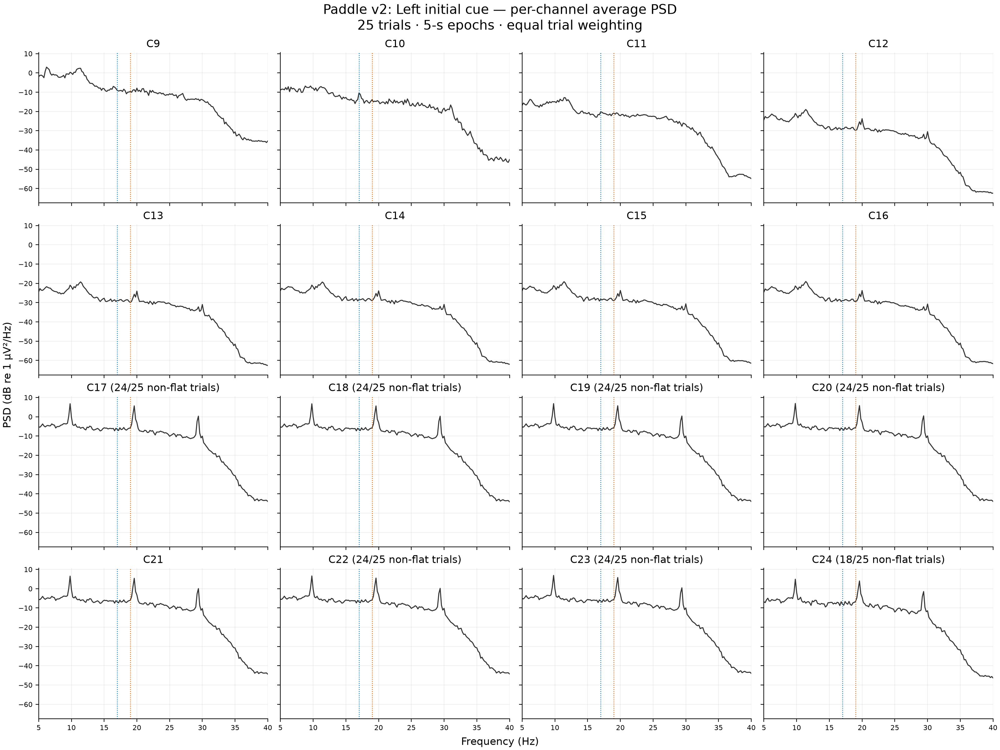


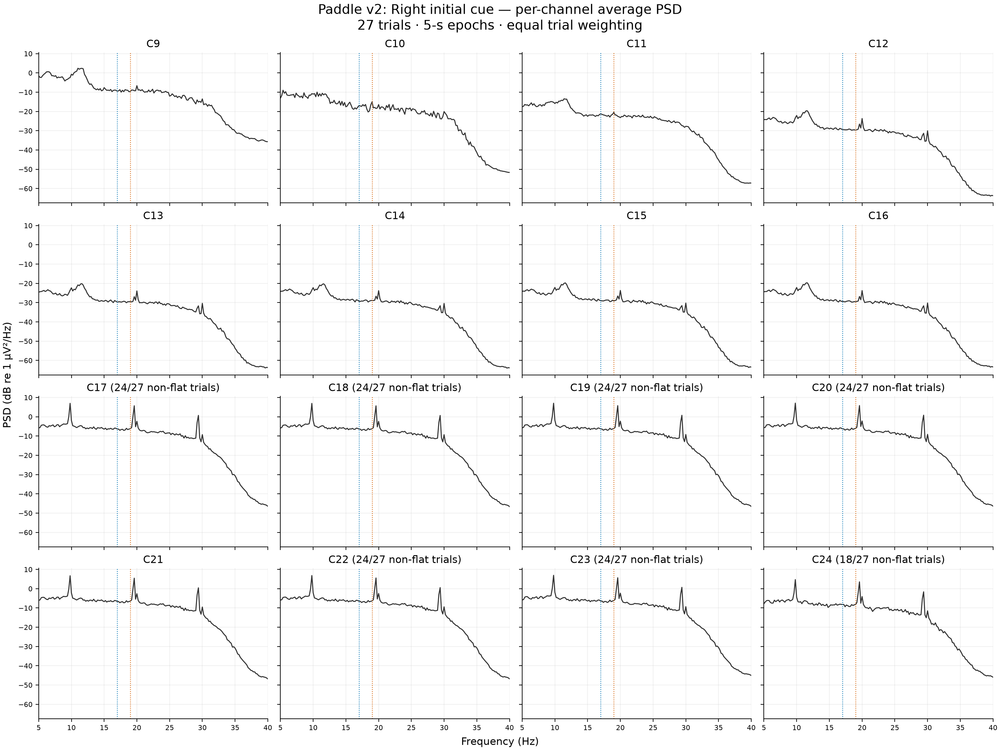


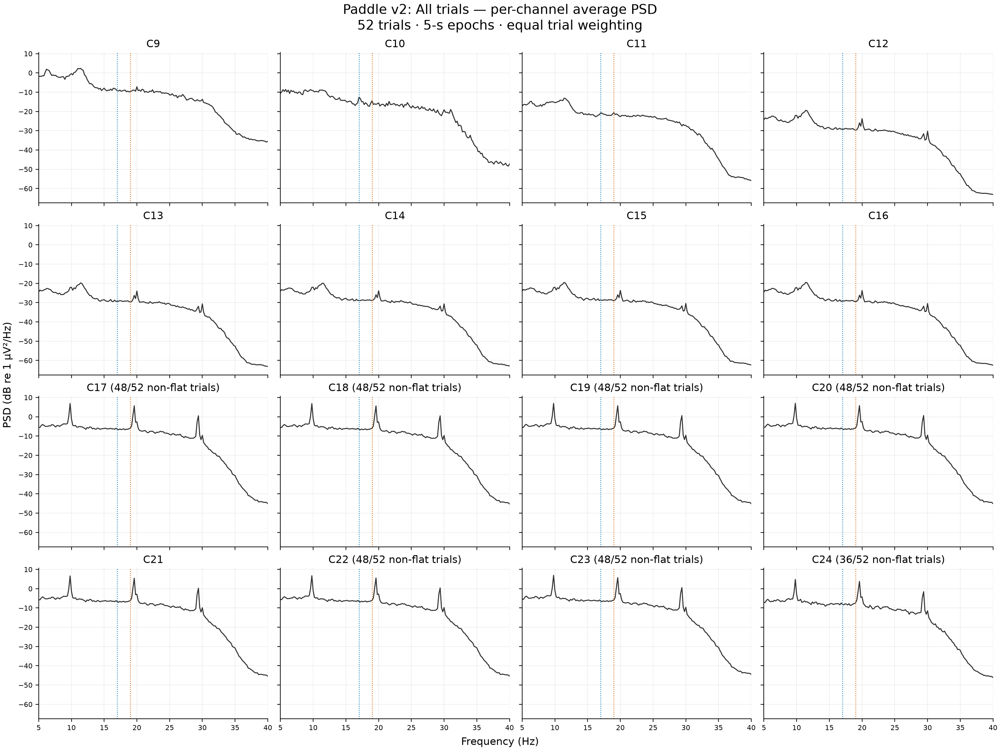


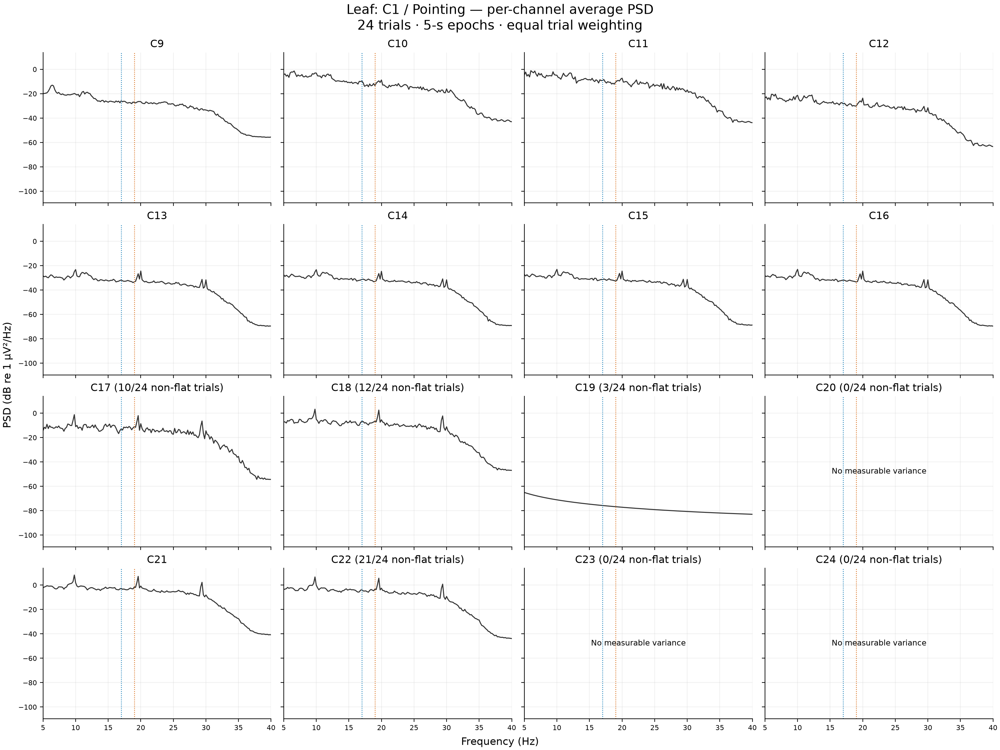


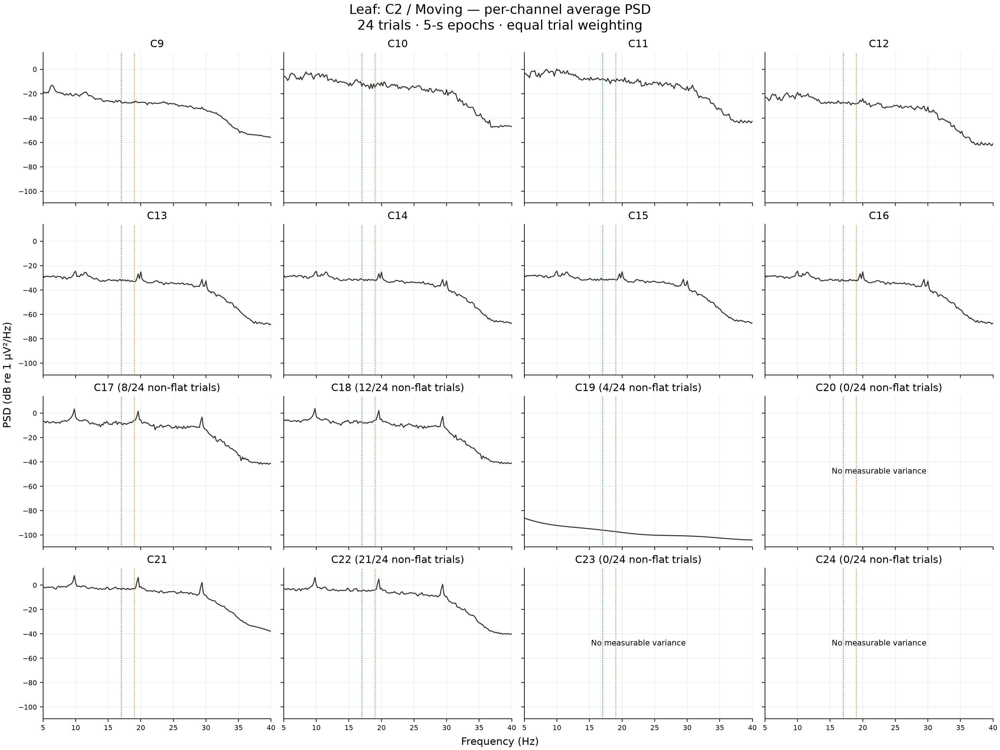


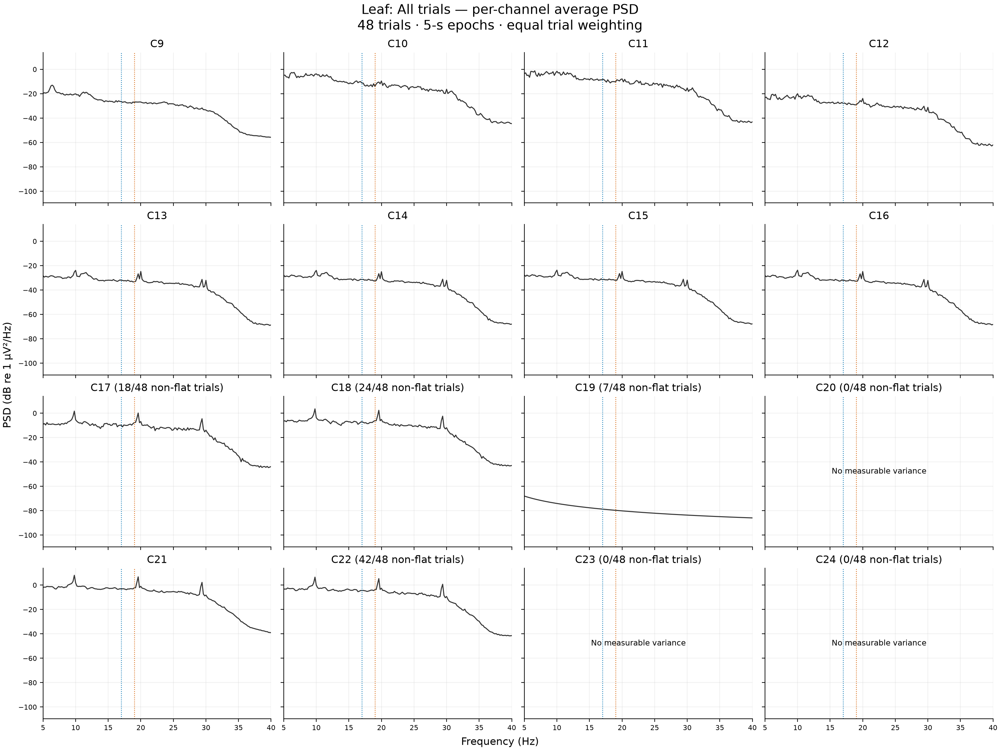

In [4]:
# Estimate spectra independently for all 16 physical channels, without spatial mixing.
channel_psd_trials = list(trials)
channel_trial_psd = {}
channel_trial_stats = []
for trial in channel_psd_trials:
    observed_seq = trial['rec']['seq'][trial['start']:trial['stop']]
    if np.any(np.diff(observed_seq) != 1) or not np.isfinite(trial['recorded_x']).all():
        raise ValueError(f'{trial["uid"]}: invalid observed EEG for channel spectra')
    powers = []
    for start in range(0, len(trial['recorded_x']), EPOCH_SAMPLES):
        frequency, power = nan_epoch_psd(trial['recorded_x'][start:start+EPOCH_SAMPLES], FS, EPOCH_SAMPLES)
        powers.append(power)
    channel_trial_psd[trial['uid']] = finite_mean(np.stack(powers), axis=0)
    for j, channel in enumerate(RECORDED_CHANNEL_NAMES):
        wave = trial['recorded_x'][:, j]
        channel_trial_stats.append(dict(uid=trial['uid'], game=trial['game'], block=trial['block'],
            condition=trial['condition'], channel=channel, samples=len(wave),
            std_uv=float(np.std(wave)), peak_to_peak_uv=float(np.ptp(wave)),
            flat_trial=bool(np.ptp(wave) == 0)))
channel_variability_audit = pd.DataFrame(channel_trial_stats)
channel_variability_audit.to_csv(INSPECTION_EXPORT_DIR / 'per_channel_variability_audit.csv', index=False)

channel_psd_summaries = {}
channel_psd_numeric = []
for game in FILES:
    for condition in [*LABELS[game].values(), None]:
        chosen = [t for t in channel_psd_trials if t['game'] == game and
                  (condition is None or t['condition'] == condition)]
        if not chosen: raise ValueError(f'No trials for {game}: {condition}')
        trial_power = np.stack([channel_trial_psd[t['uid']] for t in chosen])
        averaged = finite_mean(trial_power, axis=0)
        nonflat = np.sum([np.ptp(t['recorded_x'], axis=0) > 0 for t in chosen], axis=0)
        summary = dict(f=frequency, power=averaged, trial_power=trial_power, nonflat=nonflat,
            n=len(chosen), chosen=chosen,
            epochs=sum((len(t['recorded_x'])+EPOCH_SAMPLES-1)//EPOCH_SAMPLES for t in chosen),
            complete=sum(len(t['recorded_x'])//EPOCH_SAMPLES for t in chosen),
            partial=sum(bool(len(t['recorded_x']) % EPOCH_SAMPLES) for t in chosen))
        channel_psd_summaries[(game, condition)] = summary
        for j, channel in enumerate(RECORDED_CHANNEL_NAMES):
            channel_psd_numeric.append(pd.DataFrame(dict(game=game, condition=condition or 'All trials',
                channel=channel, frequency_hz=frequency, power_uv2_per_hz=averaged[:, j],
                trials=len(chosen), nonflat_trials=int(nonflat[j]))))
pd.concat(channel_psd_numeric, ignore_index=True).to_csv(INSPECTION_EXPORT_DIR / 'per_channel_average_spectra.csv', index=False)

def per_channel_db(power):
    # Zero power has no finite dB value; do not invent a display floor.
    power = np.asarray(power, float)
    return 10*np.log10(np.where(power > 0, power, np.nan))

def per_channel_limits(game):
    values = []
    for (g, condition), summary in channel_psd_summaries.items():
        if g != game: continue
        mask = (summary['f'] >= CHANNEL_PSD_FREQ_LIMITS[0]) & (summary['f'] <= CHANNEL_PSD_FREQ_LIMITS[1])
        db_values = per_channel_db(summary['power'][mask])
        values.extend(db_values[np.isfinite(db_values)])
    if not values: return (-1, 1)
    low, high = np.min(values), np.max(values)
    pad = max((high-low)*.05, 1)
    return low-pad, high+pad

per_channel_plot_exports = []
for game in FILES:
    for condition in [*LABELS[game].values(), None]:
        summary = channel_psd_summaries[(game, condition)]
        name = condition or 'All trials'
        fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharex=True, sharey=True,
                                 constrained_layout=True)
        mask = (summary['f'] >= CHANNEL_PSD_FREQ_LIMITS[0]) & (summary['f'] <= CHANNEL_PSD_FREQ_LIMITS[1])
        ylim = per_channel_limits(game)
        for j, (channel, ax) in enumerate(zip(RECORDED_CHANNEL_NAMES, axes.flat)):
            power = summary['power'][mask, j]
            ax.plot(summary['f'][mask], per_channel_db(power), color='#333333', lw=1.15)
            for hz, color in zip(TARGETS_HZ, ('#0072B2', '#D55E00')):
                ax.axvline(hz, color=color, ls=':', lw=.9)
            title = channel
            if summary['nonflat'][j] < summary['n']:
                title += f' ({summary["nonflat"][j]}/{summary["n"]} non-flat trials)'
            if summary['nonflat'][j] == 0:
                ax.text(.5, .5, 'No measurable variance', ha='center', va='center',
                        transform=ax.transAxes, fontsize=9)
            ax.set(title=title, xlim=CHANNEL_PSD_FREQ_LIMITS, ylim=ylim)
            ax.tick_params(labelsize=8)
        title = f'{game}: {name} — per-channel average PSD'
        fig.suptitle(f'{title}\n{summary["n"]} trials · {EPOCH_SECONDS:g}-s epochs · equal trial weighting', fontsize=15)
        fig.supxlabel('Frequency (Hz)')
        fig.supylabel('PSD (dB re 1 µV²/Hz)')
        stem = re.sub(r'[^a-z0-9]+', '_', f'per_channel_epoch{EPOCH_SECONDS:g}s_{game}_{name}'.lower()).strip('_')
        png, svg = INSPECTION_EXPORT_DIR / f'{stem}.png', INSPECTION_EXPORT_DIR / f'{stem}.svg'
        fig.savefig(png, dpi=PLOT_EXPORT_DPI); fig.savefig(svg); plt.close(fig)
        caption = (f'{summary["n"]} complete recorded trials; {summary["epochs"]} {EPOCH_SECONDS:g}-second epochs '
                   f'({summary["complete"]} complete, {summary["partial"]} partial). Each channel is analysed independently: '
                   f'PSD per epoch, mean epoch PSD within each trial, then equal trial mean in linear power. '
                   f'DPSS NW=1, K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. '
                   f'Dotted blue/orange: 17/19 Hz. '
                   f'Same y limits for every channel and condition within this game. '
                   f'Groups use the initial cue; later Paddle v2 phases can change direction.')
        encoded = base64.b64encode(png.read_bytes()).decode('ascii')
        display(HTML(f'<h3>{html.escape(title)}</h3>'
            f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto" alt="{html.escape(title)}">'
            f'<p>{html.escape(caption)}</p>'
            f'<p><a href="{html.escape(png.as_uri())}">PNG</a> · <a href="{html.escape(svg.as_uri())}">SVG</a></p>'))
        per_channel_plot_exports.append(dict(game=game, condition=name, panels=16, trials=summary['n'],
            epoch_seconds=EPOCH_SECONDS, title=title, caption=caption, png=str(png), svg=str(svg)))
pd.DataFrame(per_channel_plot_exports).to_csv(INSPECTION_EXPORT_DIR / 'per_channel_plot_manifest.csv', index=False)
assert len(per_channel_plot_exports) == 6
assert sum(row['panels'] for row in per_channel_plot_exports) == 96
print(f'6 per-channel grids (96 panels): C9-C24 separately, {EPOCH_SECONDS:g}-s epochs, {len(channel_psd_trials)} complete trials.')

## Select channels for the remaining analysis

Edit **`SELECTED_CHANNELS` in the next cell**, using the physical channel names shown above. For example, `['C9', 'C10', 'C11', 'C12']` keeps only those four channels. The default includes all 16 channels.

After editing, **run that cell and every cell below it**. The channel mean and both CCA methods will then use only this list. You can change the list and rerun from here without reloading the recordings. The inspection grids above always show all recorded channels.

The list must contain at least one channel, with no duplicates or unknown names. Channel order follows your list. CCA keeps the C16 polarity convention when C16 is selected; otherwise each fit uses its largest absolute channel weight to choose polarity. With a single selected channel, the two target projections use the same one-channel EEG waveform, although the target correlations can differ.

Each selection's figures, tables and channel list are saved in a separate subfolder under `plots/cca_30_10_<epoch length>s_epoch_plots`, so different selections can be compared.

In [5]:
# EDIT THIS LIST, then run this cell and all cells below it.
SELECTED_CHANNELS = [
    'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16'
]

def validate_selected_channels(names):
    if not isinstance(names, (list, tuple)) or not names:
        raise ValueError('SELECTED_CHANNELS must be a nonempty list, such as ["C9", "C10"].')
    if not all(isinstance(name, str) for name in names):
        raise ValueError('Use channel names as strings, such as "C9".')
    if len(set(names)) != len(names):
        raise ValueError('SELECTED_CHANNELS contains duplicate channel names.')
    unknown = [name for name in names if name not in RECORDED_CHANNEL_NAMES]
    if unknown:
        raise ValueError(f'Unknown channels: {unknown}. Available: {RECORDED_CHANNEL_NAMES}')
    return list(names), [RECORDED_CHANNEL_NAMES.index(name) for name in names]

def apply_selected_channels(names, write_exports=True):
    global CHANNEL_NAMES, CHANNEL_COLUMNS, SELECTED_CHANNEL_INDICES
    global SIGN_ANCHOR_INDEX, CHANNEL_LIST_TEXT, CHANNEL_COUNT, PLOT_EXPORT_DIR
    validated, indices = validate_selected_channels(names)
    CHANNEL_NAMES = validated
    SELECTED_CHANNEL_INDICES = indices
    CHANNEL_COLUMNS = [RECORDED_CHANNEL_COLUMNS[i] for i in indices]
    CHANNEL_COUNT = len(CHANNEL_NAMES)
    CHANNEL_LIST_TEXT = ', '.join(CHANNEL_NAMES)
    SIGN_ANCHOR_INDEX = (CHANNEL_COLUMNS.index(SIGN_ANCHOR_CHANNEL)
                         if SIGN_ANCHOR_CHANNEL in CHANNEL_COLUMNS else None)
    # Always slice the preserved full montage, including when this cell is rerun.
    for rec in records:
        rec['x'] = np.ascontiguousarray(rec['recorded_x'][:, indices])
    for trial in trials:
        trial['x'] = trial['rec']['x'][trial['start']:trial['stop']]
        for key in ('channel_mean_u', 'fixed_fits', 'fixed_u', 'update_fits',
                    'refitted_u', 'weight_seq', 'eligible'):
            trial.pop(key, None)
    tag = ('all_16_channels' if CHANNEL_NAMES == RECORDED_CHANNEL_NAMES else
           'channels_' + '_'.join(name[1:] for name in CHANNEL_NAMES))
    PLOT_EXPORT_DIR = INSPECTION_EXPORT_DIR / tag
    if write_exports:
        PLOT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        selection = pd.DataFrame(dict(channel=CHANNEL_NAMES, source_column=CHANNEL_COLUMNS,
            recorded_index_zero_based=indices, downstream_index_zero_based=range(CHANNEL_COUNT)))
        selection.to_csv(PLOT_EXPORT_DIR / 'selected_channels.csv', index=False)
        (PLOT_EXPORT_DIR / 'selected_channels.json').write_text(json.dumps(dict(
            selected_channels=CHANNEL_NAMES, recorded_channels=RECORDED_CHANNEL_NAMES,
            epoch_seconds=EPOCH_SECONDS, sample_rate_hz=FS,
            polarity_anchor='C16' if SIGN_ANCHOR_INDEX is not None else 'largest absolute weight per fit'),
            indent=2), encoding='utf-8')
    return CHANNEL_NAMES.copy()

apply_selected_channels(SELECTED_CHANNELS)
print(f'Downstream analysis uses {CHANNEL_COUNT} channels: {CHANNEL_LIST_TEXT}')
print('Results folder:', PLOT_EXPORT_DIR)
if SIGN_ANCHOR_INDEX is None:
    print('C16 is not selected: CCA polarity uses the largest absolute channel weight in each fit.')

Downstream analysis uses 8 channels: C9, C10, C11, C12, C13, C14, C15, C16
Results folder: c:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_30_10_5s_epoch_plots\channels_9_10_11_12_13_14_15_16


## Selected-channel mean power spectra

Form one waveform per complete trial by taking the arithmetic mean of **only the channels in `SELECTED_CHANNELS`**. These are the board-filtered signals in microvolts. Channels are averaged before calculating power. No CCA weights, target references, phase alignment or additional filters enter this calculation.

The 12 figures retain the same complete trials, initial-cue groups, configured epoch duration, trailing NaN handling, DPSS taper, FFT grid and 5–30 Hz frequency range as the CCA figures. For each game, the two rows compare spectrum-first averaging with waveform-first averaging.

Every figure caption records the selected channels. For N selected channels, the arithmetic mean uses weights `1/N` (weight-vector norm `1/sqrt(N)`), while CCA weights have unit norm. Absolute power differences therefore reflect both spatial weighting and this normalization.


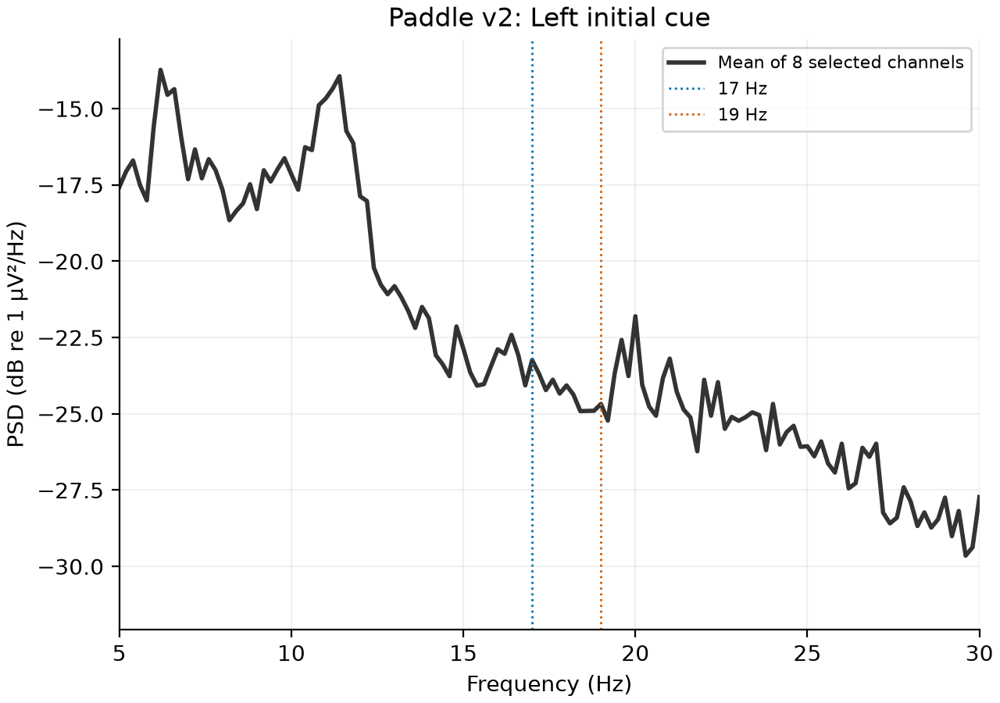
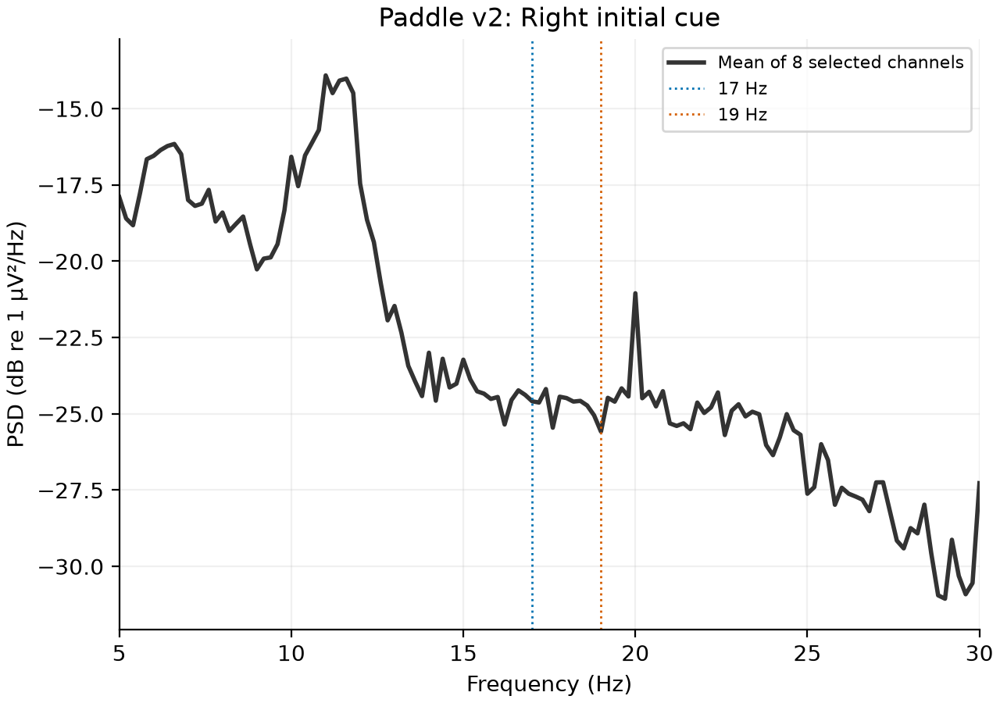
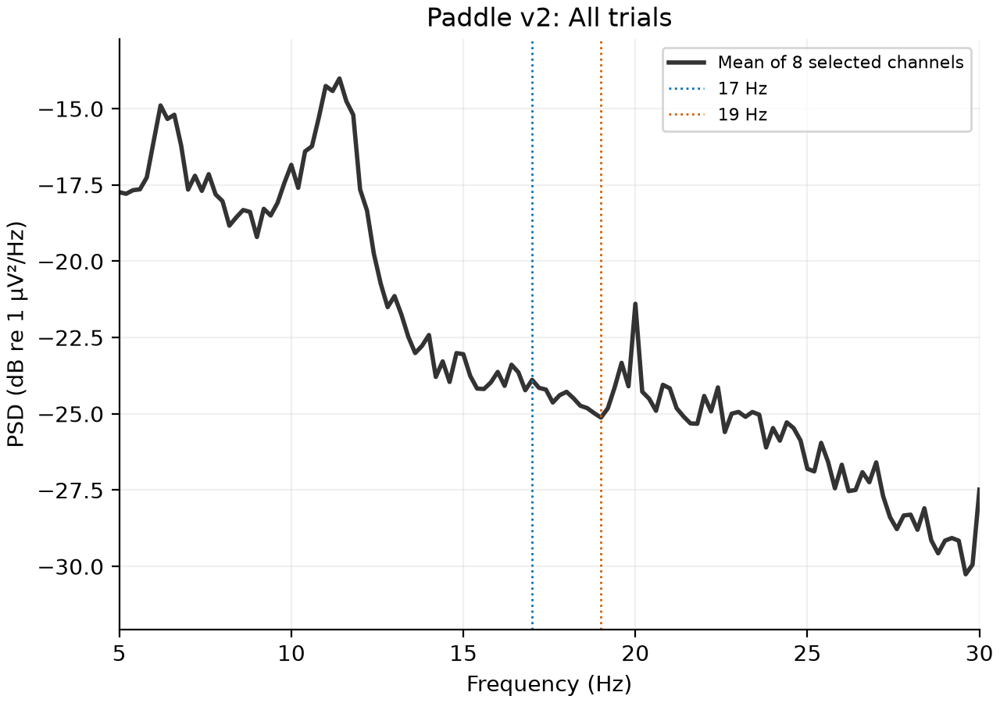
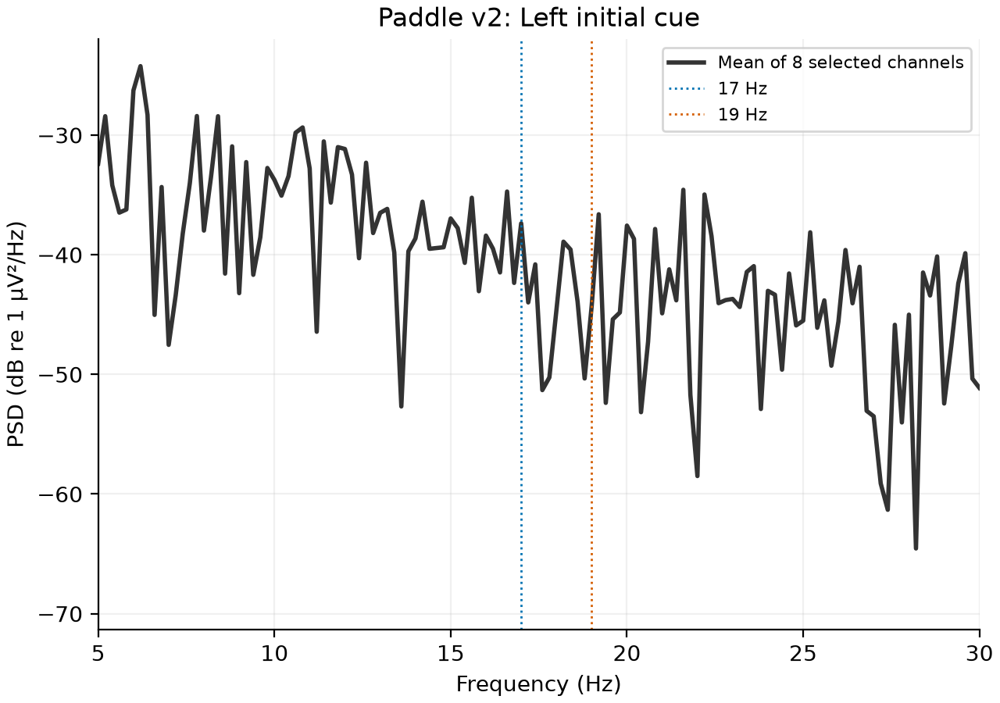
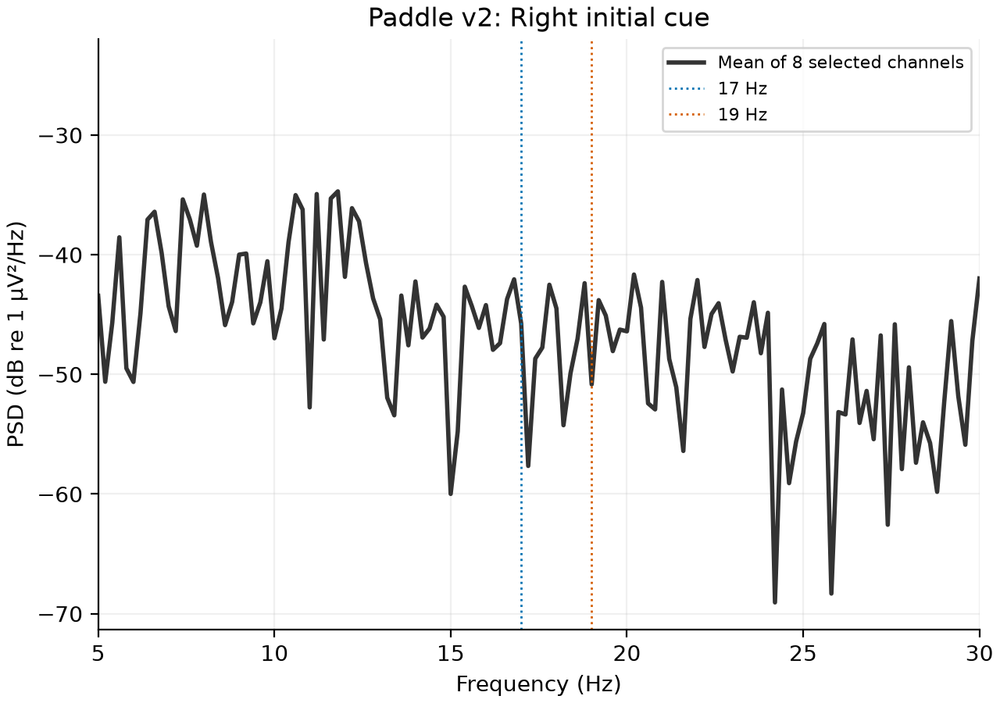
...
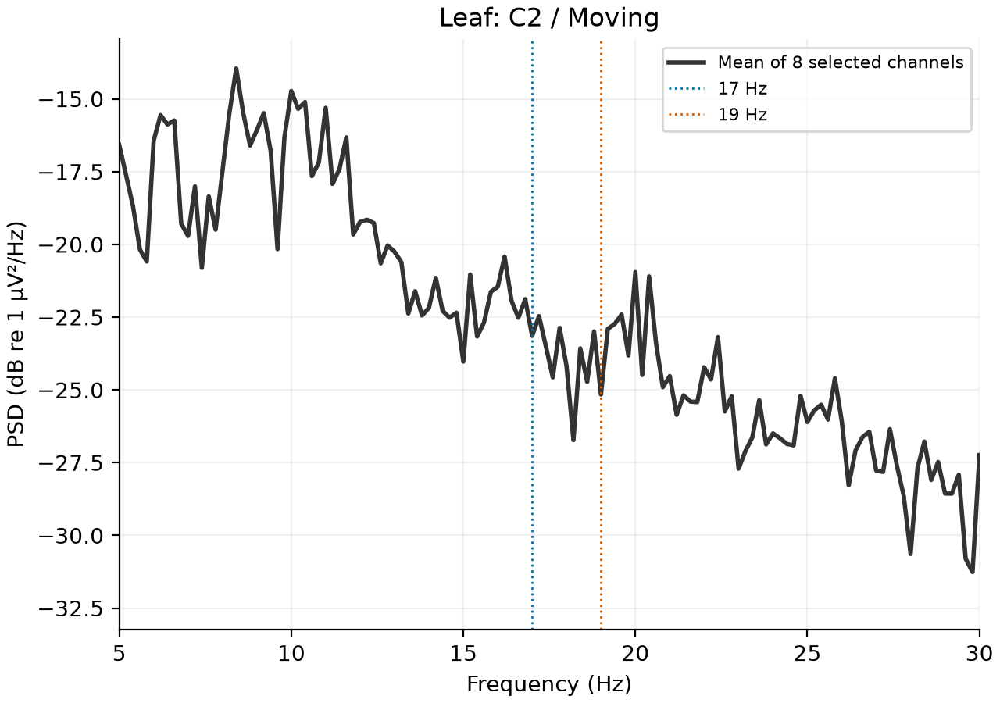
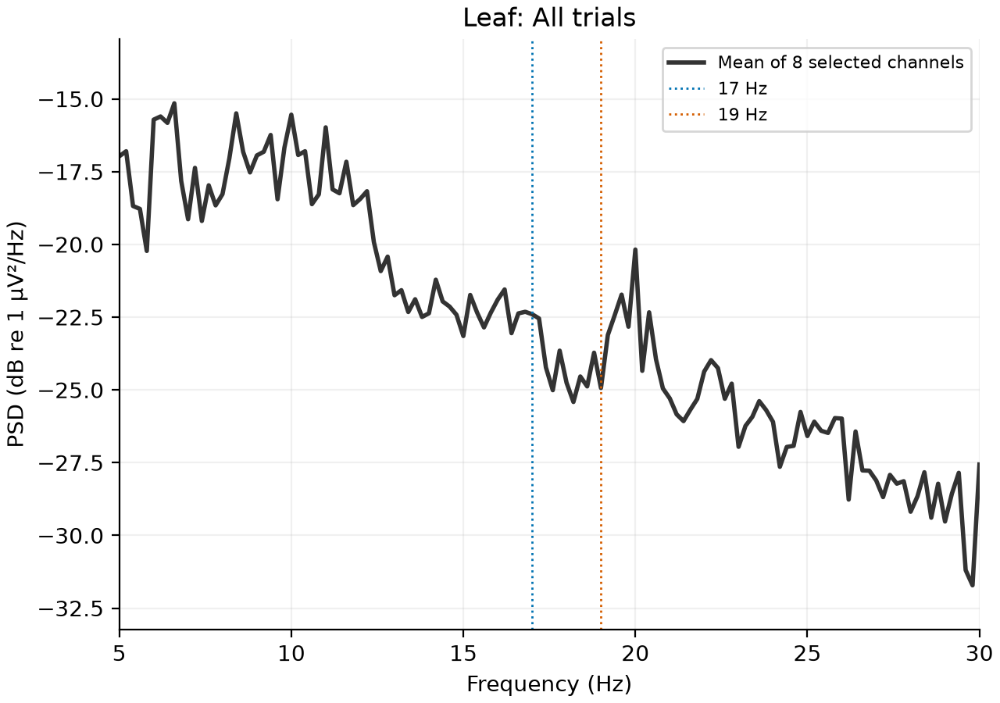
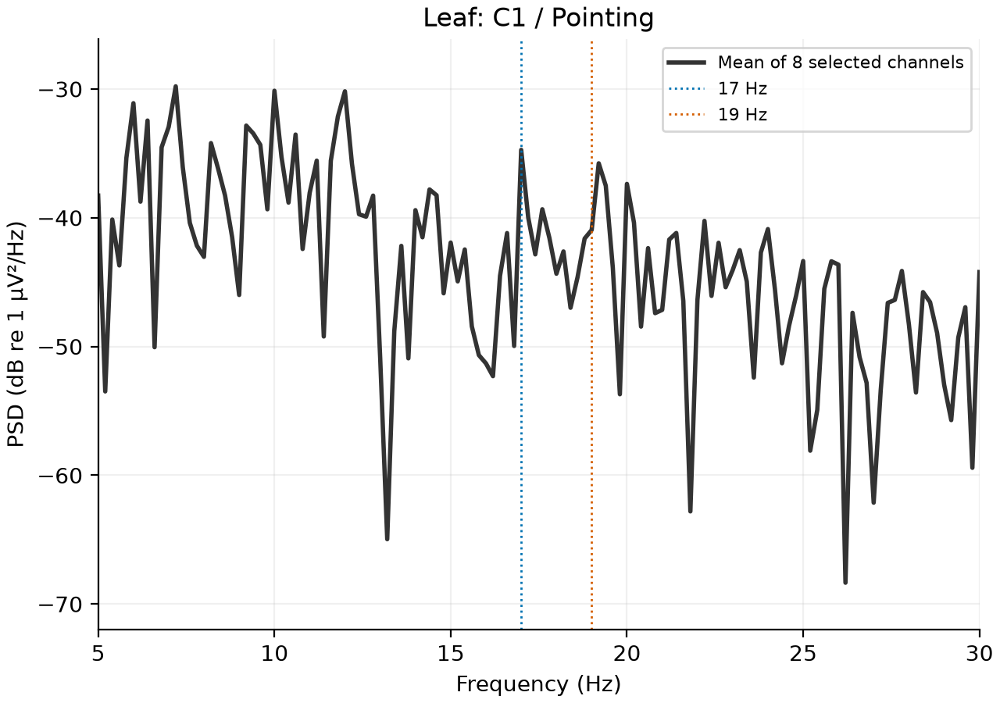
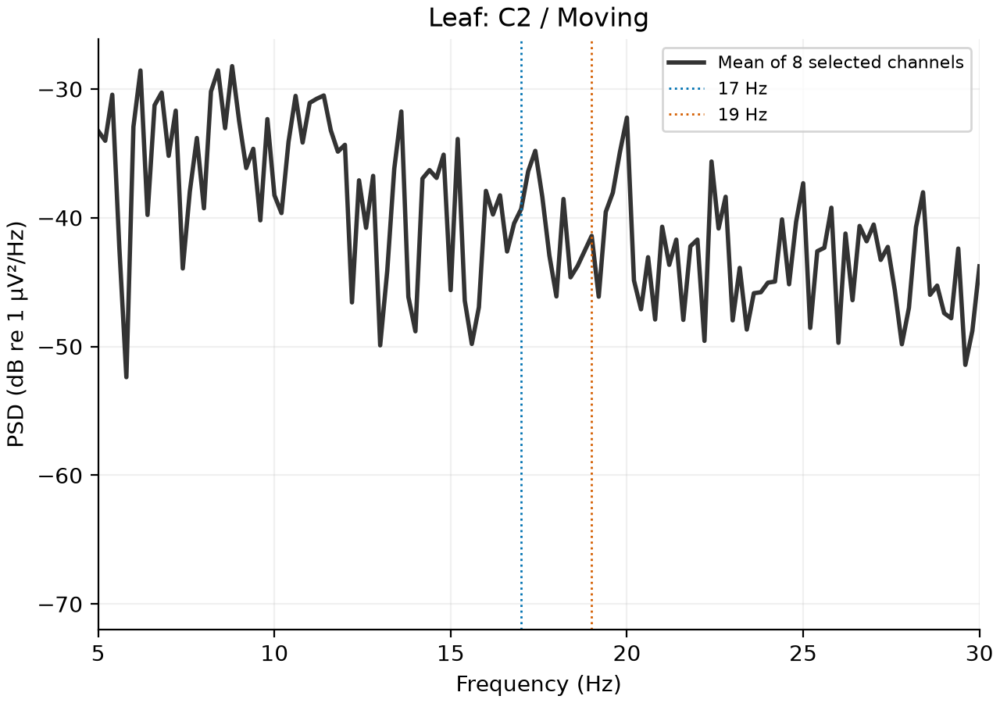
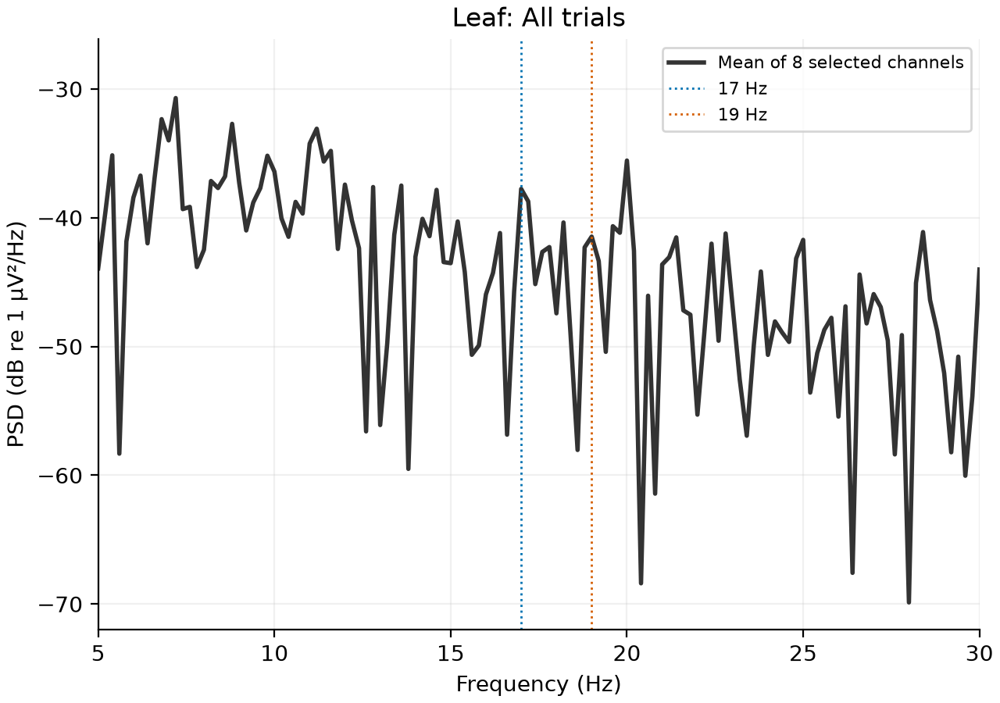

12 channel-average figures generated from 100 complete trials; CCA comparison follows.


In [6]:
# Use complete observed EEG trials; later verify identical membership to both CCA batches.
channel_mean_trials = []
for trial in trials:
    observed_seq = trial['rec']['seq'][trial['start']:trial['stop']]
    if np.any(np.diff(observed_seq) != 1) or not np.isfinite(trial['x']).all():
        raise ValueError(f'{trial["uid"]}: invalid observed EEG for channel averaging')
    trial['channel_mean_u'] = trial['x'].mean(axis=1)
    channel_mean_trials.append(trial)

channel_mean_summaries = {}
channel_mean_spectra_rows = []
for game in FILES:
    for condition in [*LABELS[game].values(), None]:
        chosen = [t for t in channel_mean_trials if t['game'] == game and
                  (condition is None or t['condition'] == condition)]
        padded = epoch_trials([t['channel_mean_u'] for t in chosen], EPOCH_SAMPLES)
        summary = pooled_trial_spectrum_orders(padded, FS)
        summary.update(n=len(chosen), epochs=sum((len(t['x'])+EPOCH_SAMPLES-1)//EPOCH_SAMPLES for t in chosen),
                       complete=sum(len(t['x'])//EPOCH_SAMPLES for t in chosen),
                       partial=sum(bool(len(t['x']) % EPOCH_SAMPLES) for t in chosen),
                       chosen=chosen, padded=padded)
        channel_mean_summaries[(game, condition)] = summary
        for order in ('induced', 'evoked'):
            for hz, power in zip(summary['f'], summary[order]):
                channel_mean_spectra_rows.append(dict(game=game, condition=condition or 'All trials',
                    order=order, selected_channels=CHANNEL_LIST_TEXT, channel_count=CHANNEL_COUNT, frequency_hz=hz, power_uv2_per_hz=power))
pd.DataFrame(channel_mean_spectra_rows).to_csv(PLOT_EXPORT_DIR / 'channel_average_spectra.csv', index=False)

channel_mean_plot_exports = []

def channel_mean_slug(*parts):
    return '_'.join(re.sub(r'[^a-z0-9]+', '_', str(p).lower()).strip('_') for p in parts)

def channel_mean_db(power):
    return 10*np.log10(np.maximum(power, np.finfo(float).tiny))

def channel_mean_limits(game, order):
    values = []
    for (g, condition), summary in channel_mean_summaries.items():
        if g != game: continue
        mask = (summary['f'] >= FREQ_LIMITS[0]) & (summary['f'] <= FREQ_LIMITS[1])
        values.extend(channel_mean_db(summary[order])[mask])
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    low, high = values.min(), values.max()
    pad = max((high-low)*.05, 1)
    return low-pad, high+pad

def channel_mean_panel(summary, game, condition, order, ylim):
    name = condition or 'All trials'
    title = f'{game}: {name}'
    fig, ax = plt.subplots(figsize=(6.4, 4.5), constrained_layout=True)
    mask = (summary['f'] >= FREQ_LIMITS[0]) & (summary['f'] <= FREQ_LIMITS[1])
    ax.plot(summary['f'][mask], channel_mean_db(summary[order])[mask], color='#333333', lw=2,
            label=f'Mean of {CHANNEL_COUNT} selected channels')
    for hz, color in zip(TARGETS_HZ, ('#0072B2', '#D55E00')):
        ax.axvline(hz, color=color, ls=':', lw=1, label=f'{hz:g} Hz')
    ax.set(title=title, xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 µV²/Hz)',
           xlim=FREQ_LIMITS, ylim=ylim)
    ax.legend(fontsize=8)
    averaging = ('Epoch PSDs averaged within each trial, then trials averaged equally' if order == 'induced' else
                 'NaN-aware epoch waveform means within trials, then equal trial waveform mean, then PSD')
    caption = (f'Channels: {CHANNEL_LIST_TEXT}. Arithmetic mean of selected voltages before power calculation; no CCA. {averaging}. '
               f'{summary["n"]} trials; {summary["epochs"]} {EPOCH_SECONDS:g}-second epochs '
               f'({summary["complete"]} complete, {summary["partial"]} partial). '
               f'Final epochs have NaN tails. Grouped by initial cue; later Paddle v2 phases may change direction. '
               f'DPSS NW=1, K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. Dotted blue/orange lines: 17/19 Hz.')
    filename = channel_mean_slug('channel_average', f'epoch{EPOCH_SECONDS:g}s', game, name, order)
    png, svg = PLOT_EXPORT_DIR / f'{filename}.png', PLOT_EXPORT_DIR / f'{filename}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    channel_mean_plot_exports.append(dict(game=game, condition=name, method='channel_mean', order=order,
        title=title, caption=caption, selected_channels=CHANNEL_LIST_TEXT, channel_count=CHANNEL_COUNT, png=str(png), svg=str(svg)))
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto;display:block" alt="{html.escape(title)}">'
            f'<p style="font-size:12px;line-height:1.4">{html.escape(caption)}</p>'
            f'<a href="{html.escape(png.as_uri())}">PNG</a> · <a href="{html.escape(svg.as_uri())}">SVG</a>')

for game in FILES:
    conditions = [*LABELS[game].values(), None]
    columns = ''.join(f'<th>{html.escape(c or "All trials")}</th>' for c in conditions)
    rows = []
    for order in ('induced', 'evoked'):
        label = 'Spectrum first → average trials' if order == 'induced' else 'Average waveforms first → spectrum'
        panels = ''.join('<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">' +
            channel_mean_panel(channel_mean_summaries[(game, c)], game, c, order,
                               channel_mean_limits(game, order)) + '</td>' for c in conditions)
        rows.append(f'<tr><td colspan="3"><strong>{html.escape(label)}</strong></td></tr><tr>{panels}</tr>')
    title = f'{game} — selected-channel mean ({CHANNEL_COUNT} channels)'
    display(HTML(f'<h3>{html.escape(title)}</h3><table style="width:100%;table-layout:fixed;border-collapse:collapse">'
                 f'<thead><tr>{columns}</tr></thead><tbody>{"".join(rows)}</tbody></table>'))
pd.DataFrame(channel_mean_plot_exports).to_csv(PLOT_EXPORT_DIR / 'channel_average_plot_manifest.csv', index=False)
assert len(channel_mean_plot_exports) == 12
print('12 channel-average figures generated from 100 complete trials; CCA comparison follows.')

## Recover the channel weights

Fit two separate CCAs: EEG versus `[sin(17 Hz), cos(17 Hz)]`, and EEG versus `[sin(19 Hz), cos(19 Hz)]`. Project centred EEG using `U17 = (X - mean_X) @ w17` and `U19 = (X - mean_X) @ w19`. Weights have unit Euclidean length; C16 supplies the polarity convention when selected; otherwise the largest absolute channel weight supplies it. Only the selected channels enter these fits.

This offline SVD analysis follows the game's reference separation and logged update timing. The firmware outputs correlation scores and uses an approximate regularized solver; the plotted waveforms are offline reconstructions, not saved board output.

In [7]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = anchor is None or abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    # A target-specific mixture supports this check even with one selected channel.
    target_ref = reference_matrix(t_test, (target,))
    target_eeg = target_ref @ rng.normal(size=(2, len(CHANNEL_COLUMNS)))
    target_eeg += rng.normal(scale=.001, size=target_eeg.shape)
    single = fit_target_cca(target_eeg, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
if len(CHANNEL_COLUMNS) >= 2:
    # Independent spatial sources require at least two selected channels.
    x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
    x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
    fit17 = fit_target_cca(x_two, t_test, 17)
    fit19 = fit_target_cca(x_two, t_test, 19)
    assert fit17['rho'] > .999999 and fit19['rho'] > .999999
    assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


## Build complete trial waveforms before epoching

**Fixed weights:** fit each target using the entire trial and apply those weights to every trial sample.

**Refitted weights:** fit the latest one second at each actual logged update. Retain only the newest samples since the preceding update (normally 100 ms), projected using that update's weights and channel means. Concatenate these nonoverlapping pieces. The first piece starts at trial onset; the endpoint covering the last trial sample supplies the final piece, cropped to the trial boundary. Each recorded sample is included exactly once and belongs to its fit's one-second input window. This reconstruction becomes available at each window endpoint; it does not predict future EEG.

Both methods use the same eligible complete trials. Fit failures and missing context are audited. Changing weight vectors can still introduce discontinuities. Epoching occurs only after these waveforms are complete.

In [8]:
trial_fit_rows = []
for trial in trials:
    rec, seq = trial['rec'], trial['rec']['seq']
    row = dict(uid=trial['uid'], game=trial['game'], condition=trial['condition'],
               channels=CHANNEL_COUNT, selected_channels=CHANNEL_LIST_TEXT, samples=len(trial['x']), duration_seconds=len(trial['x'])/FS, status='ok')
    try:
        local_seq = seq[trial['start']:trial['stop']]
        if np.any(np.diff(local_seq) != 1) or not np.isfinite(trial['x']).all():
            raise ValueError('Incomplete observed trial')
        times = (local_seq-trial['start_seq'])/FS
        trial['fixed_fits'] = [fit_target_cca(trial['x'], times, f) for f in TARGETS_HZ]
        trial['fixed_u'] = np.column_stack([fit['u'] for fit in trial['fixed_fits']])
        # Each real update contributes only the newest part of its fitted window.
        # Include the first endpoint at/after the final trial sample to cover its tail.
        after = rec['nfseq'][rec['nfseq'] >= int(local_seq[-1])]
        if not len(after):
            raise ValueError('No logged endpoint covering the final trial samples')
        updates = rec['nfseq'][(rec['nfseq'] >= trial['start_seq']) & (rec['nfseq'] <= after[0])]
        projected = np.full((len(trial['x']), len(TARGETS_HZ)), np.nan)
        assigned = np.full(len(trial['x']), -1, dtype=np.int64)
        trial['update_fits'] = []
        cursor = trial['start']
        for update in updates:
            pos = int(np.searchsorted(seq, update))
            if pos < WINDOW_SAMPLES-1 or pos >= len(seq) or seq[pos] != update:
                raise ValueError('Missing one-second fit context')
            window_seq = seq[pos-WINDOW_SAMPLES+1:pos+1]
            x = rec['x'][pos-WINDOW_SAMPLES+1:pos+1]
            if np.any(np.diff(window_seq) != 1) or not np.isfinite(x).all():
                raise ValueError('Invalid one-second fit context')
            fits = [fit_target_cca(x, (window_seq-trial['start_seq'])/FS, f) for f in TARGETS_HZ]
            lo, hi = cursor, min(trial['stop'], pos+1)
            if hi > lo:
                if lo < pos-WINDOW_SAMPLES+1:
                    raise ValueError('Logged update gap exceeds fitted window coverage')
                a, b = lo-trial['start'], hi-trial['start']
                projected[a:b] = np.column_stack([(rec['x'][lo:hi]-fit['x_mean']) @ fit['w'] for fit in fits])
                assigned[a:b] = int(update)
                cursor = hi
            trial['update_fits'].append(dict(seq=int(update), fits=fits, lo=lo, hi=hi))
        if not np.isfinite(projected).all() or np.any(assigned < 0):
            raise ValueError('Incomplete refitted waveform')
        assert np.all(assigned >= local_seq)
        assert np.all(assigned-local_seq < WINDOW_SAMPLES)
        trial['refitted_u'], trial['weight_seq'] = projected, assigned
        row['logged_fits_covering_trial'] = len(updates)
    except (ValueError, np.linalg.LinAlgError) as exc:
        row['status'] = str(exc)
    trial['eligible'] = row['status'] == 'ok'
    trial_fit_rows.append(row)
trial_fit_audit = pd.DataFrame(trial_fit_rows)
eligible_trials = [t for t in trials if t['eligible']]
print(f'{len(eligible_trials)}/{len(trials)} complete trials retained for both CCA batches.')
if len(eligible_trials) != len(trials):
    display(trial_fit_audit.loc[trial_fit_audit.status.ne('ok')])
trial_fit_audit.to_csv(PLOT_EXPORT_DIR / 'trial_fit_audit.csv', index=False)
recording_audit.to_csv(PLOT_EXPORT_DIR / 'recording_audit.csv', index=False)
assert {t['uid'] for t in eligible_trials} == {t['uid'] for t in channel_mean_trials}, 'Channel-mean/CCA trial membership differs'


100/100 complete trials retained for both CCA batches.


## Epoch the projected waveforms and calculate spectra

Split U17/U19 into consecutive epochs of `EPOCH_SECONDS`, starting at each complete marked trial's onset. With the current five-second setting these are 0–5, 5–10, 10–15 seconds, and so on. Pad the final incomplete epoch with **NaN**, and use NaN for missing epoch slots. No CCA operation occurs here.

**Spectrum first:** calculate each observed epoch's PSD, average epoch PSDs within each trial, then average trials equally in linear power.

**Waveform first:** take the NaN-aware mean of each trial's epoch waveforms, average those trial means equally using only available samples, then calculate its PSD. This folds epochs onto the configured relative time; it does not shift waveforms to align phase. The two averaging orders are generally different.

NaNs are excluded from FFT input. Each partial epoch is detrended and DPSS-tapered using its observed samples. The common FFT grid uses `EPOCH_SAMPLES` points and `FS/EPOCH_SAMPLES` Hz bins (currently 1250 points and 0.2 Hz). FFT zero padding matches bins; it does not create observed EEG or improve a short fragment's true resolution. Epochs with fewer than two observed samples have no estimable PSD and are ignored in spectrum-first averaging. Complete and partial epoch counts are exported for review.

In [9]:
epoch_audit_rows = []
for t in eligible_trials:
    n = len(t['x'])
    for k, start in enumerate(range(0, n, EPOCH_SAMPLES)):
        observed = min(EPOCH_SAMPLES, n-start)
        epoch_audit_rows.append(dict(uid=t['uid'], game=t['game'], condition=t['condition'],
            epoch=k+1, start_seconds=start/FS, observed_samples=observed,
            padded_samples=EPOCH_SAMPLES-observed, complete=observed==EPOCH_SAMPLES))
epoch_audit = pd.DataFrame(epoch_audit_rows)
epoch_audit.to_csv(PLOT_EXPORT_DIR / 'epoch_audit.csv', index=False)
summaries = {}
for game in FILES:
    for condition in [*LABELS[game].values(), None]:
        chosen = [t for t in eligible_trials if t['game'] == game and
                  (condition is None or t['condition'] == condition)]
        if not chosen:
            raise ValueError(f'No eligible trials for {game}: {condition}')
        for mode, key in [('whole', 'fixed_u'), ('refitted', 'refitted_u')]:
            padded = epoch_trials([t[key] for t in chosen], EPOCH_SAMPLES)
            summary = pooled_trial_spectrum_orders(padded, FS)
            summary.update(n=len(chosen), epochs=sum((len(t['x'])+EPOCH_SAMPLES-1)//EPOCH_SAMPLES for t in chosen),
                           complete=sum(len(t['x'])//EPOCH_SAMPLES for t in chosen),
                           partial=sum(bool(len(t['x']) % EPOCH_SAMPLES) for t in chosen), padded=padded,
                           chosen=chosen)
            summaries[(game, condition, mode)] = summary

## The two batches of plots

Within each game table, columns select the initial left/right cue for Paddle v2, C1/C2 for Leaf, or all trials. The top row calculates spectra before averaging; the bottom averages waveforms before calculating spectra. Every image is independent, with PNG and SVG links. The group counts reflect available EEG, including only four trials from the third Paddle block.


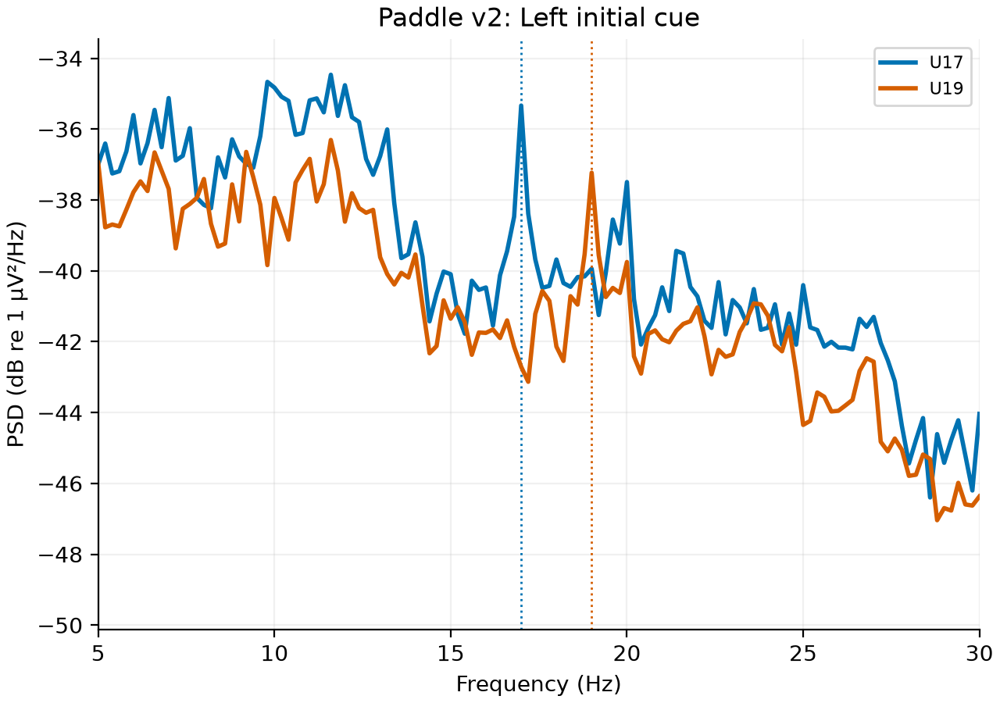
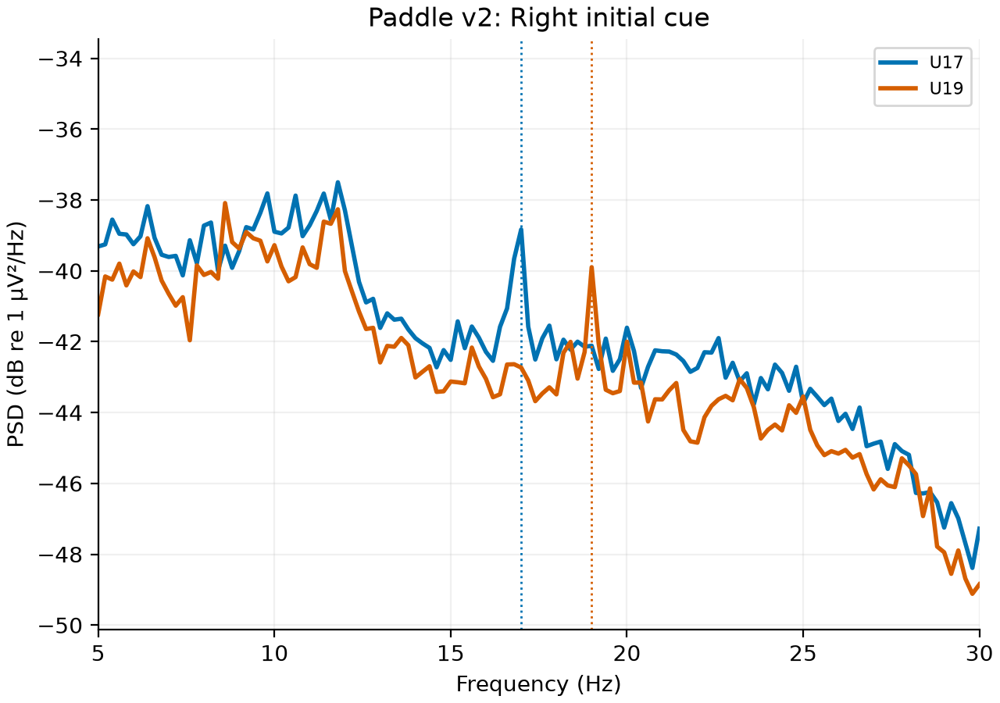
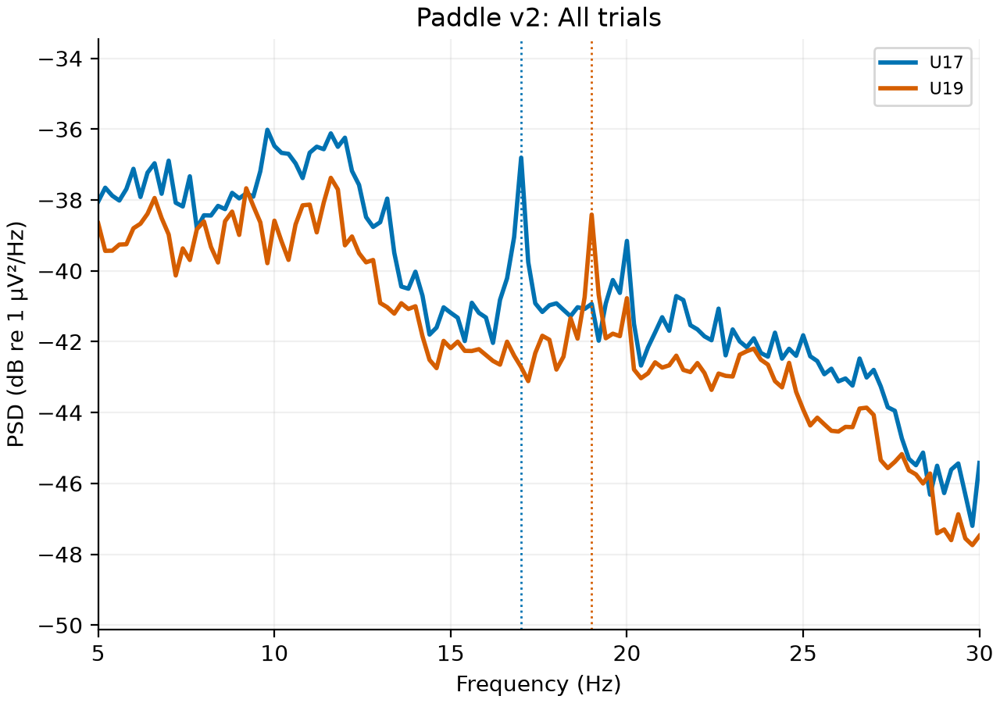
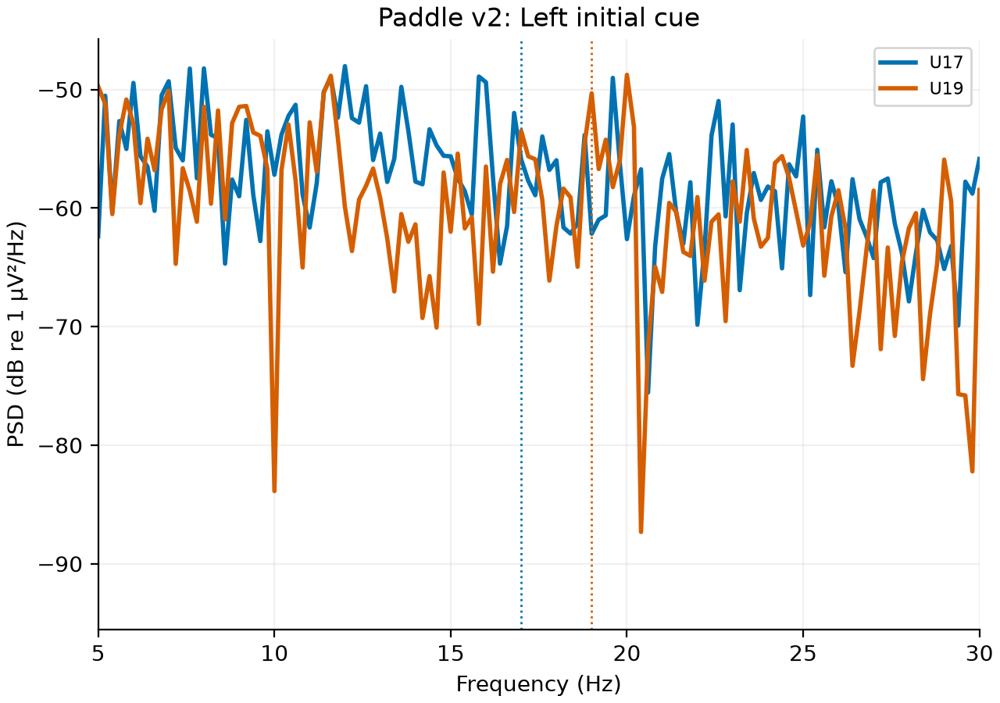
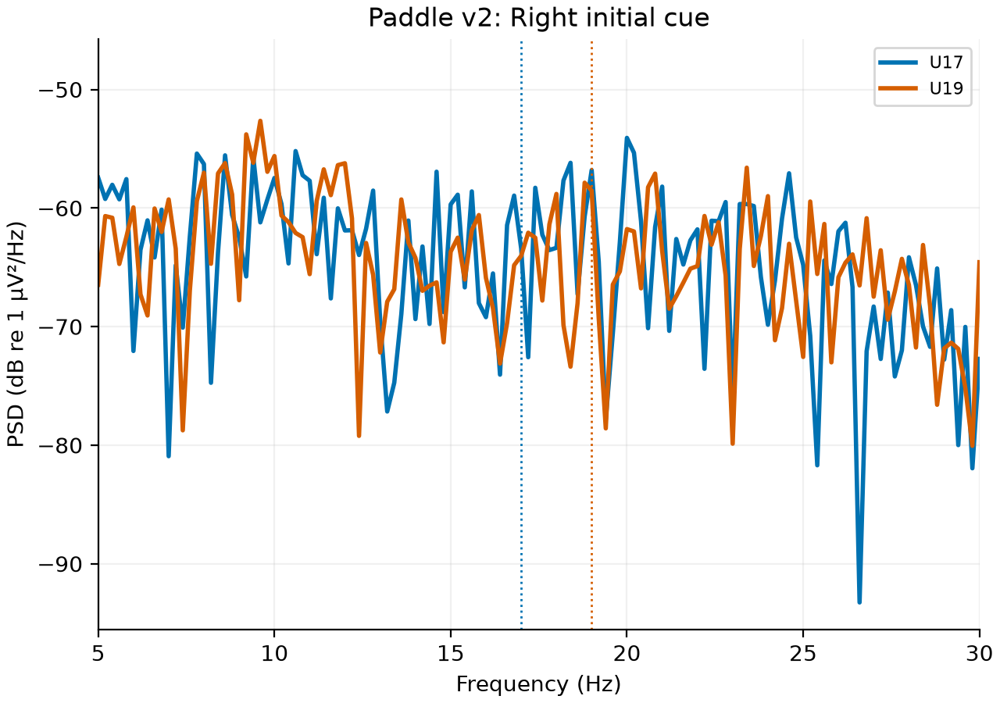
...
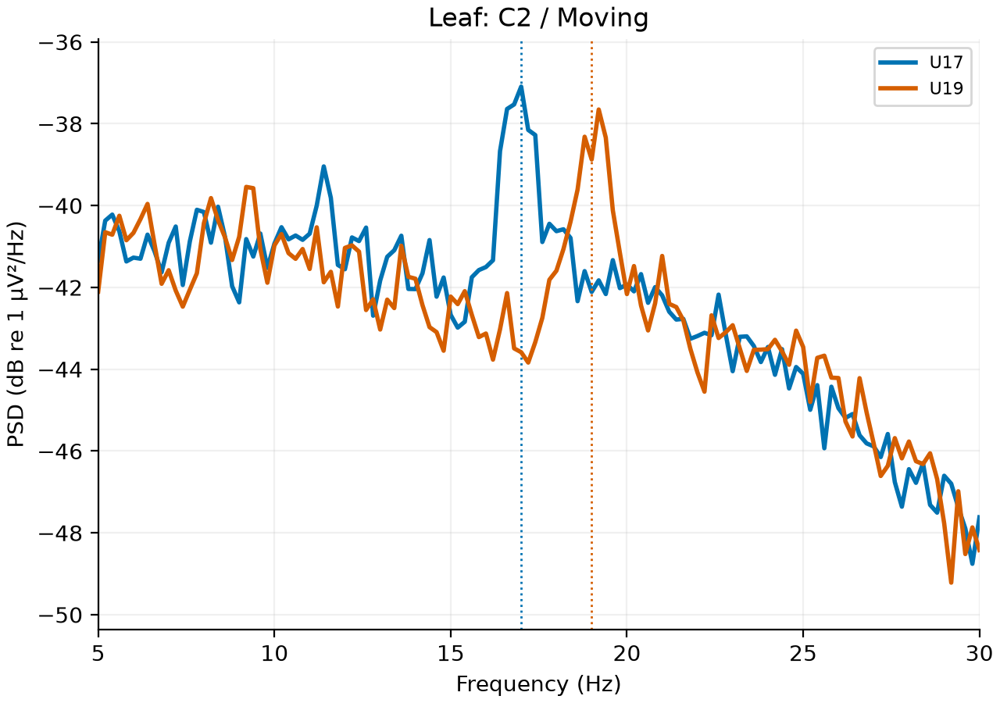
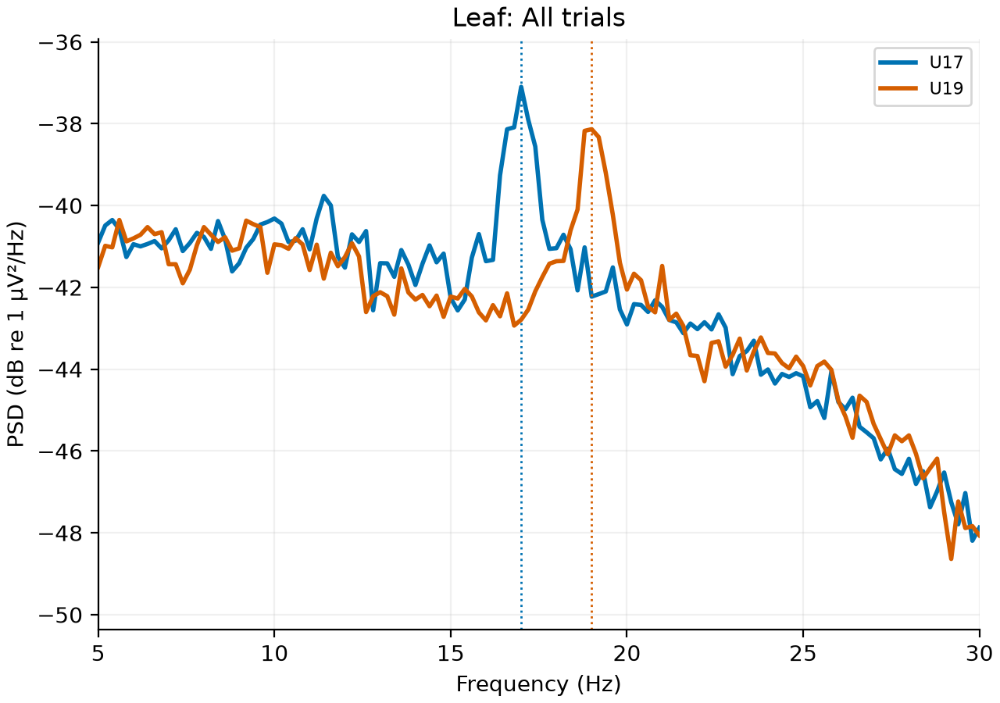
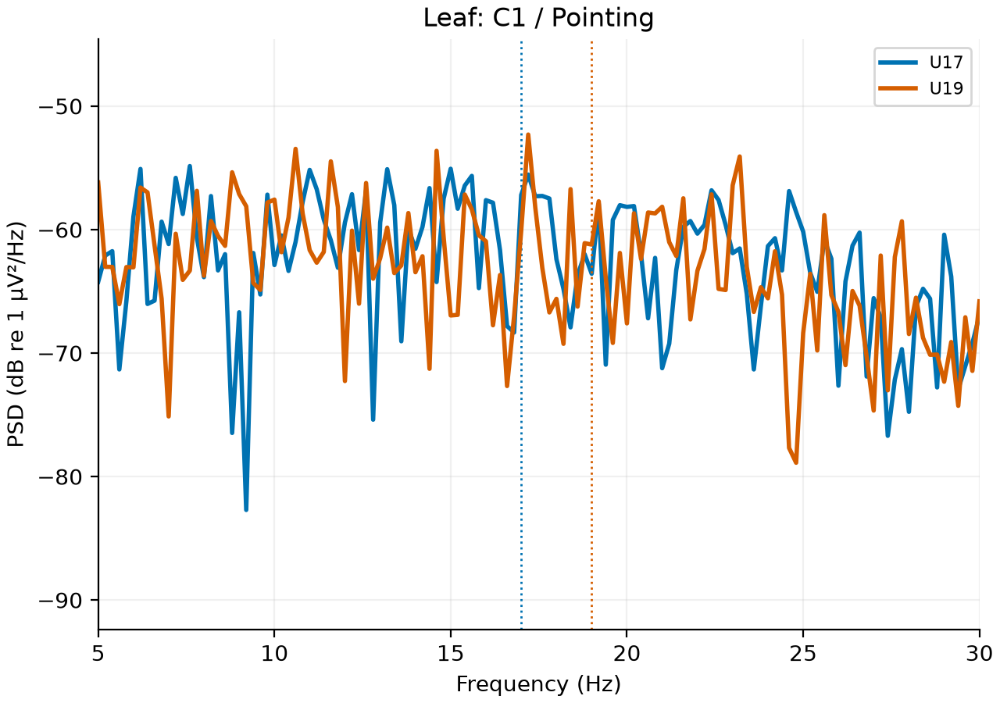
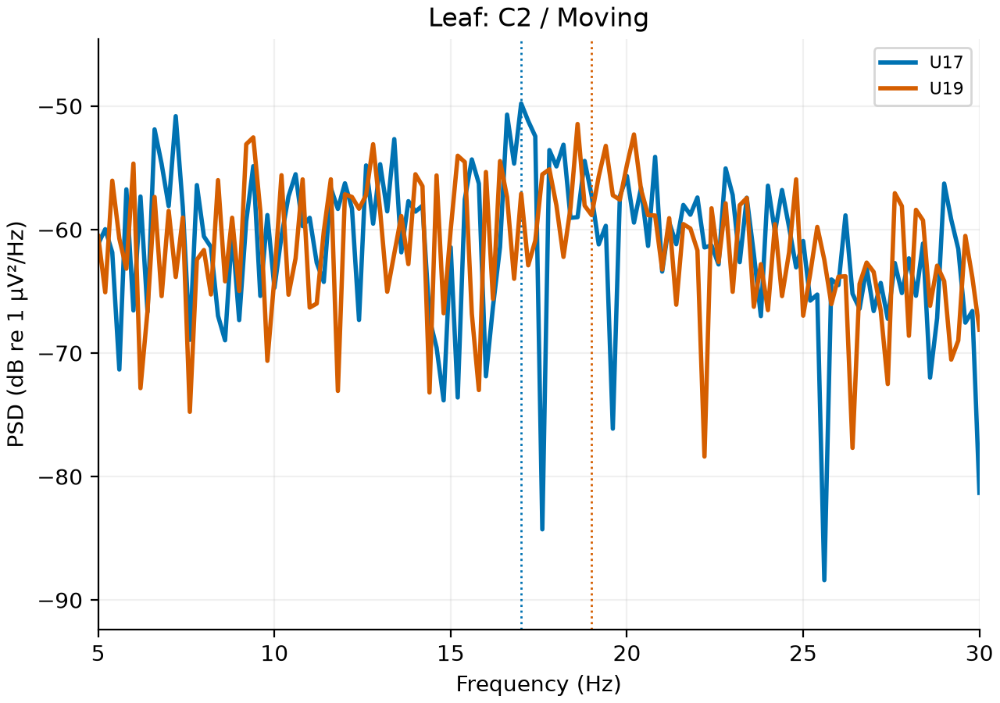
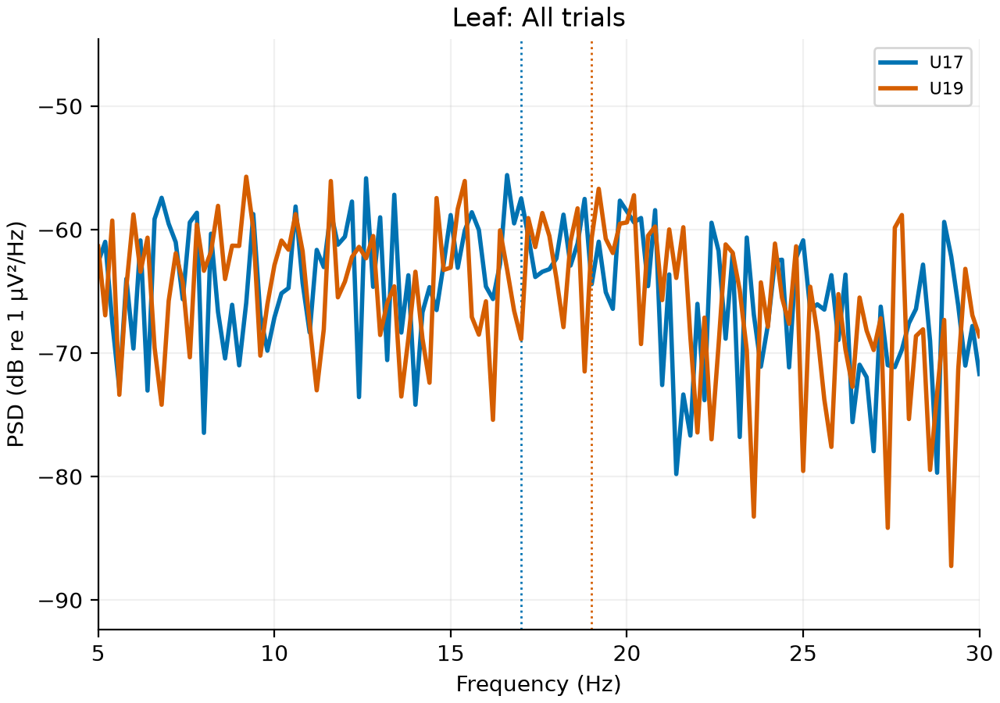

24 independent figures: 12 fixed-weight and 12 refitted-weight; PNG/SVG files in c:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_30_10_5s_epoch_plots\channels_9_10_11_12_13_14_15_16


In [10]:
plot_exports = []
def slug(*parts):
    return '_'.join(re.sub(r'[^a-z0-9]+', '_', str(p).lower()).strip('_') for p in parts)

def db_plot(power):
    return 10*np.log10(np.maximum(power, np.finfo(float).tiny))

def common_limits(game, order):
    values = []
    for (g, condition, mode), s in summaries.items():
        if g != game:
            continue
        mask = (s['f'] >= FREQ_LIMITS[0]) & (s['f'] <= FREQ_LIMITS[1])
        values.extend(db_plot(s[order])[mask].ravel())
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    low, high = values.min(), values.max()
    pad = max((high-low)*.05, 1)
    return low-pad, high+pad

def spectrum_panel(s, game, condition, mode, order, ylim):
    name = condition or 'All trials'
    title = f'{game}: {name}'
    fig, ax = plt.subplots(figsize=(6.4, 4.5), constrained_layout=True)
    mask = (s['f'] >= FREQ_LIMITS[0]) & (s['f'] <= FREQ_LIMITS[1])
    for j, (hz, color) in enumerate(zip(TARGETS_HZ, ('#0072B2', '#D55E00'))):
        ax.plot(s['f'][mask], db_plot(s[order])[mask, j], color=color, lw=2, label=f'U{hz:g}')
        ax.axvline(hz, color=color, ls=':', lw=1)
    ax.set(title=title, xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 µV²/Hz)', xlim=FREQ_LIMITS, ylim=ylim)
    ax.legend(fontsize=8)
    method = ('CCA weights fitted once using each entire trial' if mode == 'whole' else
              'CCA weights refitted on the latest 1 s every logged NF update (~100 ms)')
    averaging = ('Epoch PSDs averaged within each trial, then trials averaged equally' if order == 'induced' else
                 'NaN-aware epoch waveform means within trials, then equal trial waveform mean, then PSD')
    caption = (f'Channels: {CHANNEL_LIST_TEXT}. {method}. {averaging}. {s["n"]} trials; {s["epochs"]} {EPOCH_SECONDS:g}-second epochs '
               f'({s["complete"]} complete, {s["partial"]} partial). Final epochs have NaN tails. '
               f'Grouped by initial cue; later Paddle v2 phases may change direction. Blue: U17; orange: U19. DPSS NW=1, K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid.')
    filename = slug(f'epoch{EPOCH_SECONDS:g}s', game, name, mode, order)
    png, svg = PLOT_EXPORT_DIR / f'{filename}.png', PLOT_EXPORT_DIR / f'{filename}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    plot_exports.append(dict(game=game, condition=name, method=mode, order=order, title=title,
                             caption=caption, selected_channels=CHANNEL_LIST_TEXT, channel_count=CHANNEL_COUNT, png=str(png), svg=str(svg)))
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto;display:block" alt="{html.escape(title)}">'
            f'<p style="font-size:12px;line-height:1.4">{html.escape(caption)}</p>'
            f'<a href="{html.escape(png.as_uri())}">PNG</a> · <a href="{html.escape(svg.as_uri())}">SVG</a>')

for mode in ('whole', 'refitted'):
    for game in FILES:
        conditions = [*LABELS[game].values(), None]
        title = f'{game} — ' + ('fixed whole-trial CCA weights' if mode == 'whole' else 'CCA weights refitted every 100 ms')
        columns = ''.join(f'<th>{html.escape(c or "All trials")}</th>' for c in conditions)
        rows = []
        for order in ('induced', 'evoked'):
            label = 'Spectrum first → average trials' if order == 'induced' else 'Average waveforms first → spectrum'
            panels = ''.join('<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">' +
                spectrum_panel(summaries[(game, c, mode)], game, c, mode, order, common_limits(game, order)) + '</td>'
                for c in conditions)
            rows.append(f'<tr><td colspan="3"><strong>{html.escape(label)}</strong></td></tr><tr>{panels}</tr>')
        display(HTML(f'<h3>{html.escape(title)}</h3><table style="width:100%;table-layout:fixed;border-collapse:collapse">'
                     f'<thead><tr>{columns}</tr></thead><tbody>{"".join(rows)}</tbody></table>'))
pd.DataFrame(plot_exports).to_csv(PLOT_EXPORT_DIR / 'plot_manifest.csv', index=False)
assert len(plot_exports) == 24
print('24 independent figures: 12 fixed-weight and 12 refitted-weight; PNG/SVG files in', PLOT_EXPORT_DIR)

## Verify epoch coverage and padding

Check that epoching preserves every observed waveform sample, pads only missing tails, uses equal trial weighting, and produces exactly the requested 24 independent figures.

Also verify that all 12 channel-average figures use exactly the same trial membership and spectral bins as the CCA comparisons (36 figures overall).

In [11]:
fragment = max(2, min(17, EPOCH_SAMPLES-1))
short = max(2, EPOCH_SAMPLES//2)
probe = epoch_trials([np.arange(float(EPOCH_SAMPLES+fragment)), np.arange(float(short))], EPOCH_SAMPLES)
assert probe.shape == (2, 2, EPOCH_SAMPLES)
assert np.array_equal(probe[0, 0], np.arange(float(EPOCH_SAMPLES)))
assert np.array_equal(probe[0, 1, :fragment], np.arange(float(EPOCH_SAMPLES), float(EPOCH_SAMPLES+fragment)))
assert np.isnan(probe[0, 1, fragment:]).all() and np.isnan(probe[1, 1]).all()
for (game, condition, mode), s in summaries.items():
    key = 'fixed_u' if mode == 'whole' else 'refitted_u'
    for i, t in enumerate(s['chosen']):
        flattened = s['padded'][i].reshape(-1, len(TARGETS_HZ))
        assert np.array_equal(flattened[:len(t['x'])], t[key])
        assert np.isnan(flattened[len(t['x']):]).all()
    assert np.allclose(s['induced'], finite_mean(s['trial_power'], axis=0))
    assert np.allclose(s['evoked'], nan_epoch_psd(s['mean_epoch'], FS, EPOCH_SAMPLES)[1])
    assert np.isfinite(s['induced']).all() and np.isfinite(s['evoked']).all()
    assert np.isclose(np.diff(s['f']), FS/EPOCH_SAMPLES).all()
for t in eligible_trials:
    assert len(t['fixed_u']) == len(t['refitted_u']) == len(t['x'])
    for update in t['update_fits']:
        if update['hi'] > update['lo']:
            a, b = update['lo']-t['start'], update['hi']-t['start']
            expected = np.column_stack([(t['x'][a:b]-fit['x_mean']) @ fit['w'] for fit in update['fits']])
            assert np.allclose(t['refitted_u'][a:b], expected)
assert len(plot_exports) == 24
assert len({r['png'] for r in plot_exports}) == 24
assert all(Path(r[ext]).is_file() for r in plot_exports for ext in ('png', 'svg'))
assert epoch_audit.observed_samples.sum() == sum(len(t['x']) for t in eligible_trials)
assert epoch_audit.groupby('uid').observed_samples.sum().sum() == sum(len(t['x']) for t in eligible_trials)
print(f'All {len(eligible_trials)} complete projected trials retained; {EPOCH_SECONDS:g}-second epoch coverage, NaN tails, both orders and 24 figures verified.')
assert trial_fit_audit.status.eq('ok').all(), 'Review excluded trials before interpreting pooled plots'
assert len(eligible_trials) == 100
assert pd.Series([t['game'] for t in eligible_trials]).value_counts().to_dict() == {'Paddle v2': 52, 'Leaf': 48}
assert all(len(t['x']) == t['stop_seq']-t['start_seq'] for t in eligible_trials)
assert not any(t['rec']['recording'] == 'eeg_20261030_124553' for t in eligible_trials)
assert {t['trial'] for t in eligible_trials if t['rec']['recording'] == 'eeg_20261030_124401'} == {21, 22, 23, 24}
print('October 30 coverage verified: 52 Paddle v2 + 48 Leaf; no incomplete trials included.')

assert len(channel_mean_plot_exports) == 12
assert len({r['png'] for r in channel_mean_plot_exports}) == 12
assert all(Path(r[ext]).is_file() for r in channel_mean_plot_exports for ext in ('png', 'svg'))
for (game, condition), summary in channel_mean_summaries.items():
    for mode in ('whole', 'refitted'):
        cca_summary = summaries[(game, condition, mode)]
        assert {t['uid'] for t in summary['chosen']} == {t['uid'] for t in cca_summary['chosen']}
        assert np.array_equal(summary['f'], cca_summary['f'])
        assert (summary['n'], summary['epochs'], summary['complete'], summary['partial']) == (cca_summary['n'], cca_summary['epochs'], cca_summary['complete'], cca_summary['partial'])
    for i, t in enumerate(summary['chosen']):
        observed = summary['padded'][i].reshape(-1)[:len(t['x'])]
        assert np.array_equal(observed, t['x'].mean(axis=1))
    assert np.allclose(summary['induced'], finite_mean(summary['trial_power'], axis=0))
    assert np.allclose(summary['evoked'], nan_epoch_psd(summary['mean_epoch'], FS, EPOCH_SAMPLES)[1])
print('12 channel-average + 24 CCA figures verified; identical trials, epochs and FFT grids.')

assert {t['uid'] for t in channel_psd_trials} == {t['uid'] for t in eligible_trials}
for (game, condition), summary in channel_psd_summaries.items():
    baseline = channel_mean_summaries[(game, condition)]
    assert {t['uid'] for t in summary['chosen']} == {t['uid'] for t in baseline['chosen']}
    assert np.array_equal(summary['f'], baseline['f'])
    assert summary['power'].shape == (EPOCH_SAMPLES//2+1, len(RECORDED_CHANNEL_NAMES))
    assert np.isfinite(summary['power']).all() and np.all(summary['power'] >= 0)
    assert np.allclose(summary['power'], finite_mean(summary['trial_power'], axis=0))
    assert (summary['n'], summary['epochs'], summary['complete'], summary['partial']) == (baseline['n'], baseline['epochs'], baseline['complete'], baseline['partial'])
# Verify the multichannel calculation against an independent single-channel path on recorded EEG.
probe_trial = channel_psd_trials[0]
for j in [0, len(RECORDED_CHANNEL_NAMES)-1]:
    expected = finite_mean(np.stack([nan_epoch_psd(probe_trial['recorded_x'][start:start+EPOCH_SAMPLES, j], FS, EPOCH_SAMPLES)[1]
        for start in range(0, len(probe_trial['recorded_x']), EPOCH_SAMPLES)]), axis=0)
    assert np.allclose(channel_trial_psd[probe_trial['uid']][:, j], expected)
assert len(channel_variability_audit) == len(channel_psd_trials)*len(RECORDED_CHANNEL_NAMES)
assert len(per_channel_plot_exports) == 6
assert all(Path(row[ext]).is_file() for row in per_channel_plot_exports for ext in ('png', 'svg'))
print('Per-channel grids verified: 16 independent channels, six groups, matching trials/epochs and equal trial weighting.')

assert CHANNEL_NAMES == SELECTED_CHANNELS
for rec in records:
    assert rec['recorded_x'].shape[1] == len(RECORDED_CHANNEL_NAMES)
    assert np.array_equal(rec['x'], rec['recorded_x'][:, SELECTED_CHANNEL_INDICES])
for t in eligible_trials:
    assert t['x'].shape[1] == CHANNEL_COUNT
    assert np.array_equal(t['x'], t['recorded_x'][:, SELECTED_CHANNEL_INDICES])
    assert all(fit['w'].shape == (CHANNEL_COUNT,) for fit in t['fixed_fits'])
    assert all(fit['w'].shape == (CHANNEL_COUNT,) for update in t['update_fits'] for fit in update['fits'])
assert PLOT_EXPORT_DIR.is_relative_to(INSPECTION_EXPORT_DIR)
assert json.loads((PLOT_EXPORT_DIR / 'selected_channels.json').read_text())['selected_channels'] == CHANNEL_NAMES
print(f'Selection verified: all downstream means and CCA fits use only {CHANNEL_LIST_TEXT}; inspection retains all 16 channels.')


All 100 complete projected trials retained; 5-second epoch coverage, NaN tails, both orders and 24 figures verified.
October 30 coverage verified: 52 Paddle v2 + 48 Leaf; no incomplete trials included.
12 channel-average + 24 CCA figures verified; identical trials, epochs and FFT grids.
Per-channel grids verified: 16 independent channels, six groups, matching trials/epochs and equal trial weighting.
Selection verified: all downstream means and CCA fits use only C9, C10, C11, C12, C13, C14, C15, C16; inspection retains all 16 channels.
